<center><h1>Enriquez_Scott_HW4</h1></center>
<br>
<br>

Name: Scott Enriquez
<br>
Github Username: `scottenriquez`
<br>

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
%pip install -q bootstrapped==0.0.2 matplotlib==3.11.2 numpy==2.5.3 "pandas[output-formatting]==3.0.6" scikit-learn==1.9.1 seaborn==0.13.2 statsmodels==0.15.0

Note: you may need to restart the kernel to use updated packages.


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
import seaborn as sns
from sklearn.metrics import accuracy_score
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm

Get the AReM Data Set

In [3]:
arem_columns = ['time', 'avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23']
bending1_dataset_csv_count = len(list(Path('AReM/bending1').glob('*.csv')))
bending2_dataset_csv_count = len(list(Path('AReM/bending2').glob('*.csv')))
cycling_dataset_csv_count = len(list(Path('AReM/cycling').glob('*.csv')))
lying_dataset_csv_count = len(list(Path('AReM/lying').glob('*.csv')))
sitting_dataset_csv_count = len(list(Path('AReM/sitting').glob('*.csv')))
standing_dataset_csv_count = len(list(Path('AReM/standing').glob('*.csv')))
walking_dataset_csv_count = len(list(Path('AReM/walking').glob('*.csv')))

### (b) Splitting Data

In [4]:
def read_activity_dataset_csv_file(activity: str, dataset_index: int, is_training_data: bool) -> pd.DataFrame:
    activity_dataset = pd.read_csv(f'AReM/{activity}/dataset{dataset_index}.csv', engine='python', comment='#',
                                   names=arem_columns, sep=r'[,\s]+', usecols=range(7))
    activity_dataset['instance'] = f'{activity}_{dataset_index}'
    activity_dataset['activity'] = ''.join([character for character in activity if not character.isdigit()])
    activity_dataset['is_training_data'] = is_training_data
    return activity_dataset

In [5]:
test_data = pd.concat(
    [read_activity_dataset_csv_file(activity, index, is_training_data=False) for activity in ['bending1', 'bending2']
     for index in
     range(1, 3)] +
    [read_activity_dataset_csv_file(activity, index, is_training_data=False) for activity in
     ['cycling', 'lying', 'sitting', 'standing', 'walking'] for index in range(1, 4)],
    ignore_index=True
)
display(test_data)

,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23,instance,activity,is_training_data
0,0,39.25,0.43,22.75,0.43,33.75,1.30,bending1_1,bending,False
1,250,39.25,0.43,23.00,0.00,33.00,0.00,bending1_1,bending,False
2,500,39.25,0.43,23.25,0.43,33.00,0.00,bending1_1,bending,False
3,750,39.50,0.50,23.00,0.71,33.00,0.00,bending1_1,bending,False
4,1000,39.50,0.50,24.00,0.00,33.00,0.00,bending1_1,bending,False
...,...,...,...,...,...,...,...,...,...,...
9115,118750,36.00,2.45,17.00,5.10,20.50,0.87,walking_3,walking,False
9116,119000,34.33,1.89,15.00,2.45,17.00,2.12,walking_3,walking,False
9117,119250,33.00,7.35,14.60,3.14,13.00,5.70,walking_3,walking,False
9118,119500,31.67,1.25,11.00,6.16,19.25,2.17,walking_3,walking,False


In [6]:
training_data = pd.concat(
    [read_activity_dataset_csv_file('bending1', index, is_training_data=True) for index in
     range(3, bending1_dataset_csv_count + 1)] +
    [read_activity_dataset_csv_file('bending2', index, is_training_data=True) for index in
     range(3, bending2_dataset_csv_count + 1)] +
    [read_activity_dataset_csv_file('cycling', index, is_training_data=True) for index in
     range(4, cycling_dataset_csv_count + 1)] +
    [read_activity_dataset_csv_file('lying', index, is_training_data=True) for index in
     range(4, lying_dataset_csv_count + 1)] +
    [read_activity_dataset_csv_file('sitting', index, is_training_data=True) for index in
     range(4, sitting_dataset_csv_count + 1)] +
    [read_activity_dataset_csv_file('standing', index, is_training_data=True) for index in
     range(4, standing_dataset_csv_count + 1)] +
    [read_activity_dataset_csv_file('walking', index, is_training_data=True) for index in
     range(4, walking_dataset_csv_count + 1)],
    ignore_index=True
)
display(training_data)

,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23,instance,activity,is_training_data
0,0,42.00,0.71,21.25,0.43,30.00,0.00,bending1_3,bending,True
1,250,41.50,0.50,20.25,1.48,31.25,1.09,bending1_3,bending,True
2,500,41.50,0.50,14.25,1.92,33.00,0.00,bending1_3,bending,True
3,750,40.75,0.83,15.75,0.43,33.00,0.00,bending1_3,bending,True
4,1000,40.00,0.71,20.00,2.74,32.75,0.43,bending1_3,bending,True
...,...,...,...,...,...,...,...,...,...,...
33114,118750,34.50,6.18,9.00,3.56,12.67,4.19,walking_15,walking,True
33115,119000,25.75,6.02,13.75,2.05,16.00,1.58,walking_15,walking,True
33116,119250,31.50,3.35,10.25,5.12,16.25,2.95,walking_15,walking,True
33117,119500,33.75,2.77,14.00,3.24,13.75,0.43,walking_15,walking,True


### (c) Feature Extraction

In [7]:
def extract_features(data: pd.DataFrame, splits: int = 1) -> pd.DataFrame:
    instance_index = 1
    aggregated_instances = []
    feature_columns = [column for column in data.columns if
                       column not in ['time', 'instance', 'activity', 'is_training_data']]
    for instance, instance_data in data.groupby('instance'):
        aggregated_instance = {'instance_index': instance_index, 'instance': instance}
        for split_index, split_positions in enumerate(np.array_split(np.arange(len(instance_data)), splits), start=1):
            split_data = instance_data.iloc[split_positions]
            for feature in feature_columns:
                split_feature = feature if splits == 1 else f'{feature}_{split_index}'
                aggregated_instance[f'minimum_{split_feature}'] = split_data[feature].min()
                aggregated_instance[f'maximum_{split_feature}'] = split_data[feature].max()
                aggregated_instance[f'mean_{split_feature}'] = split_data[feature].mean()
                aggregated_instance[f'median_{split_feature}'] = split_data[feature].median()
                aggregated_instance[f'standard_deviation_{split_feature}'] = split_data[feature].std()
                first_quartile, third_quartile = split_data[feature].quantile([0.25, 0.75])
                aggregated_instance[f'first_quartile_{split_feature}'] = first_quartile
                aggregated_instance[f'third_quartile_{split_feature}'] = third_quartile
        aggregated_instance['is_training_data'] = instance_data['is_training_data'].iloc[0]
        aggregated_instance['activity'] = instance_data['activity'].iloc[0]
        aggregated_instances.append(aggregated_instance)
        instance_index += 1
    return pd.DataFrame(aggregated_instances).set_index('instance_index')


extracted_features_data = extract_features(pd.concat([training_data, test_data], ignore_index=True), splits=1)
display(extracted_features_data)

,instance,minimum_avg_rss12,maximum_avg_rss12,mean_avg_rss12,median_avg_rss12,standard_deviation_avg_rss12,first_quartile_avg_rss12,third_quartile_avg_rss12,minimum_var_rss12,maximum_var_rss12,...,third_quartile_avg_rss23,minimum_var_rss23,maximum_var_rss23,mean_var_rss23,median_var_rss23,standard_deviation_var_rss23,first_quartile_var_rss23,third_quartile_var_rss23,is_training_data,activity
instance_index,,,,,,,,,,,,,,,,,,,,,
1,bending1_1,37.25,45.00,40.624792,40.500,1.476967,39.25,42.0000,0.0,1.30,...,36.00,0.0,1.92,0.570583,0.430,0.582915,0.00,1.3000,False,bending
2,bending1_2,38.00,45.67,42.812812,42.500,1.435550,42.00,43.6700,0.0,1.22,...,34.50,0.0,3.11,0.571083,0.430,0.601010,0.00,1.3000,False,bending
3,bending1_3,35.00,47.40,43.954500,44.330,1.558835,43.00,45.0000,0.0,1.70,...,36.50,0.0,1.79,0.493292,0.430,0.513506,0.00,0.9400,True,bending
4,bending1_4,33.00,47.75,42.179812,43.500,3.670666,39.15,45.0000,0.0,3.00,...,36.33,0.0,2.18,0.613521,0.500,0.524317,0.00,1.0000,True,bending
5,bending1_5,33.00,45.75,41.678063,41.750,2.243490,41.33,42.7500,0.0,2.83,...,31.25,0.0,1.79,0.383292,0.430,0.389164,0.00,0.5000,True,bending
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,walking_5,20.75,46.25,34.763333,35.290,4.742208,31.67,38.2500,0.0,12.68,...,18.33,0.0,9.39,3.288271,3.270,1.647528,2.05,4.3050,True,walking
85,walking_6,21.50,51.00,34.935812,35.500,4.645944,32.00,38.0625,0.0,12.21,...,18.25,0.0,10.21,3.280021,3.015,1.700918,2.12,4.5000,True,walking
86,walking_7,18.33,47.67,34.333042,34.750,4.948770,31.25,38.0000,0.0,12.48,...,18.00,0.0,8.01,3.261583,2.980,1.617290,2.05,4.3200,True,walking


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

Note that I chose mean, maximum, and standard deviation for my three statistics in the previous assignment. In all binary classification code below, `1` refers to bending and `0` refers to all other activities.

In [8]:
binary_classification_data = extracted_features_data.copy(deep=True)
binary_classification_data.loc[binary_classification_data['activity'] != 'bending', 'bending_class'] = 0
binary_classification_data.loc[binary_classification_data['activity'] == 'bending', 'bending_class'] = 1
binary_classification_data['bending_class'] = binary_classification_data['bending_class'].astype(int)
training_binary_classification_data = binary_classification_data[binary_classification_data['is_training_data'] == True]
test_binary_classification_data = binary_classification_data[binary_classification_data['is_training_data'] != True]
plot_columns_2ai = ['bending_class']
for statistic in ['mean', 'maximum', 'standard_deviation']:
    for feature in ['avg_rss12', 'var_rss12', 'var_rss23']:
        plot_columns_2ai.append(f'{statistic}_{feature}')
plot_data_2ai = training_binary_classification_data[plot_columns_2ai]

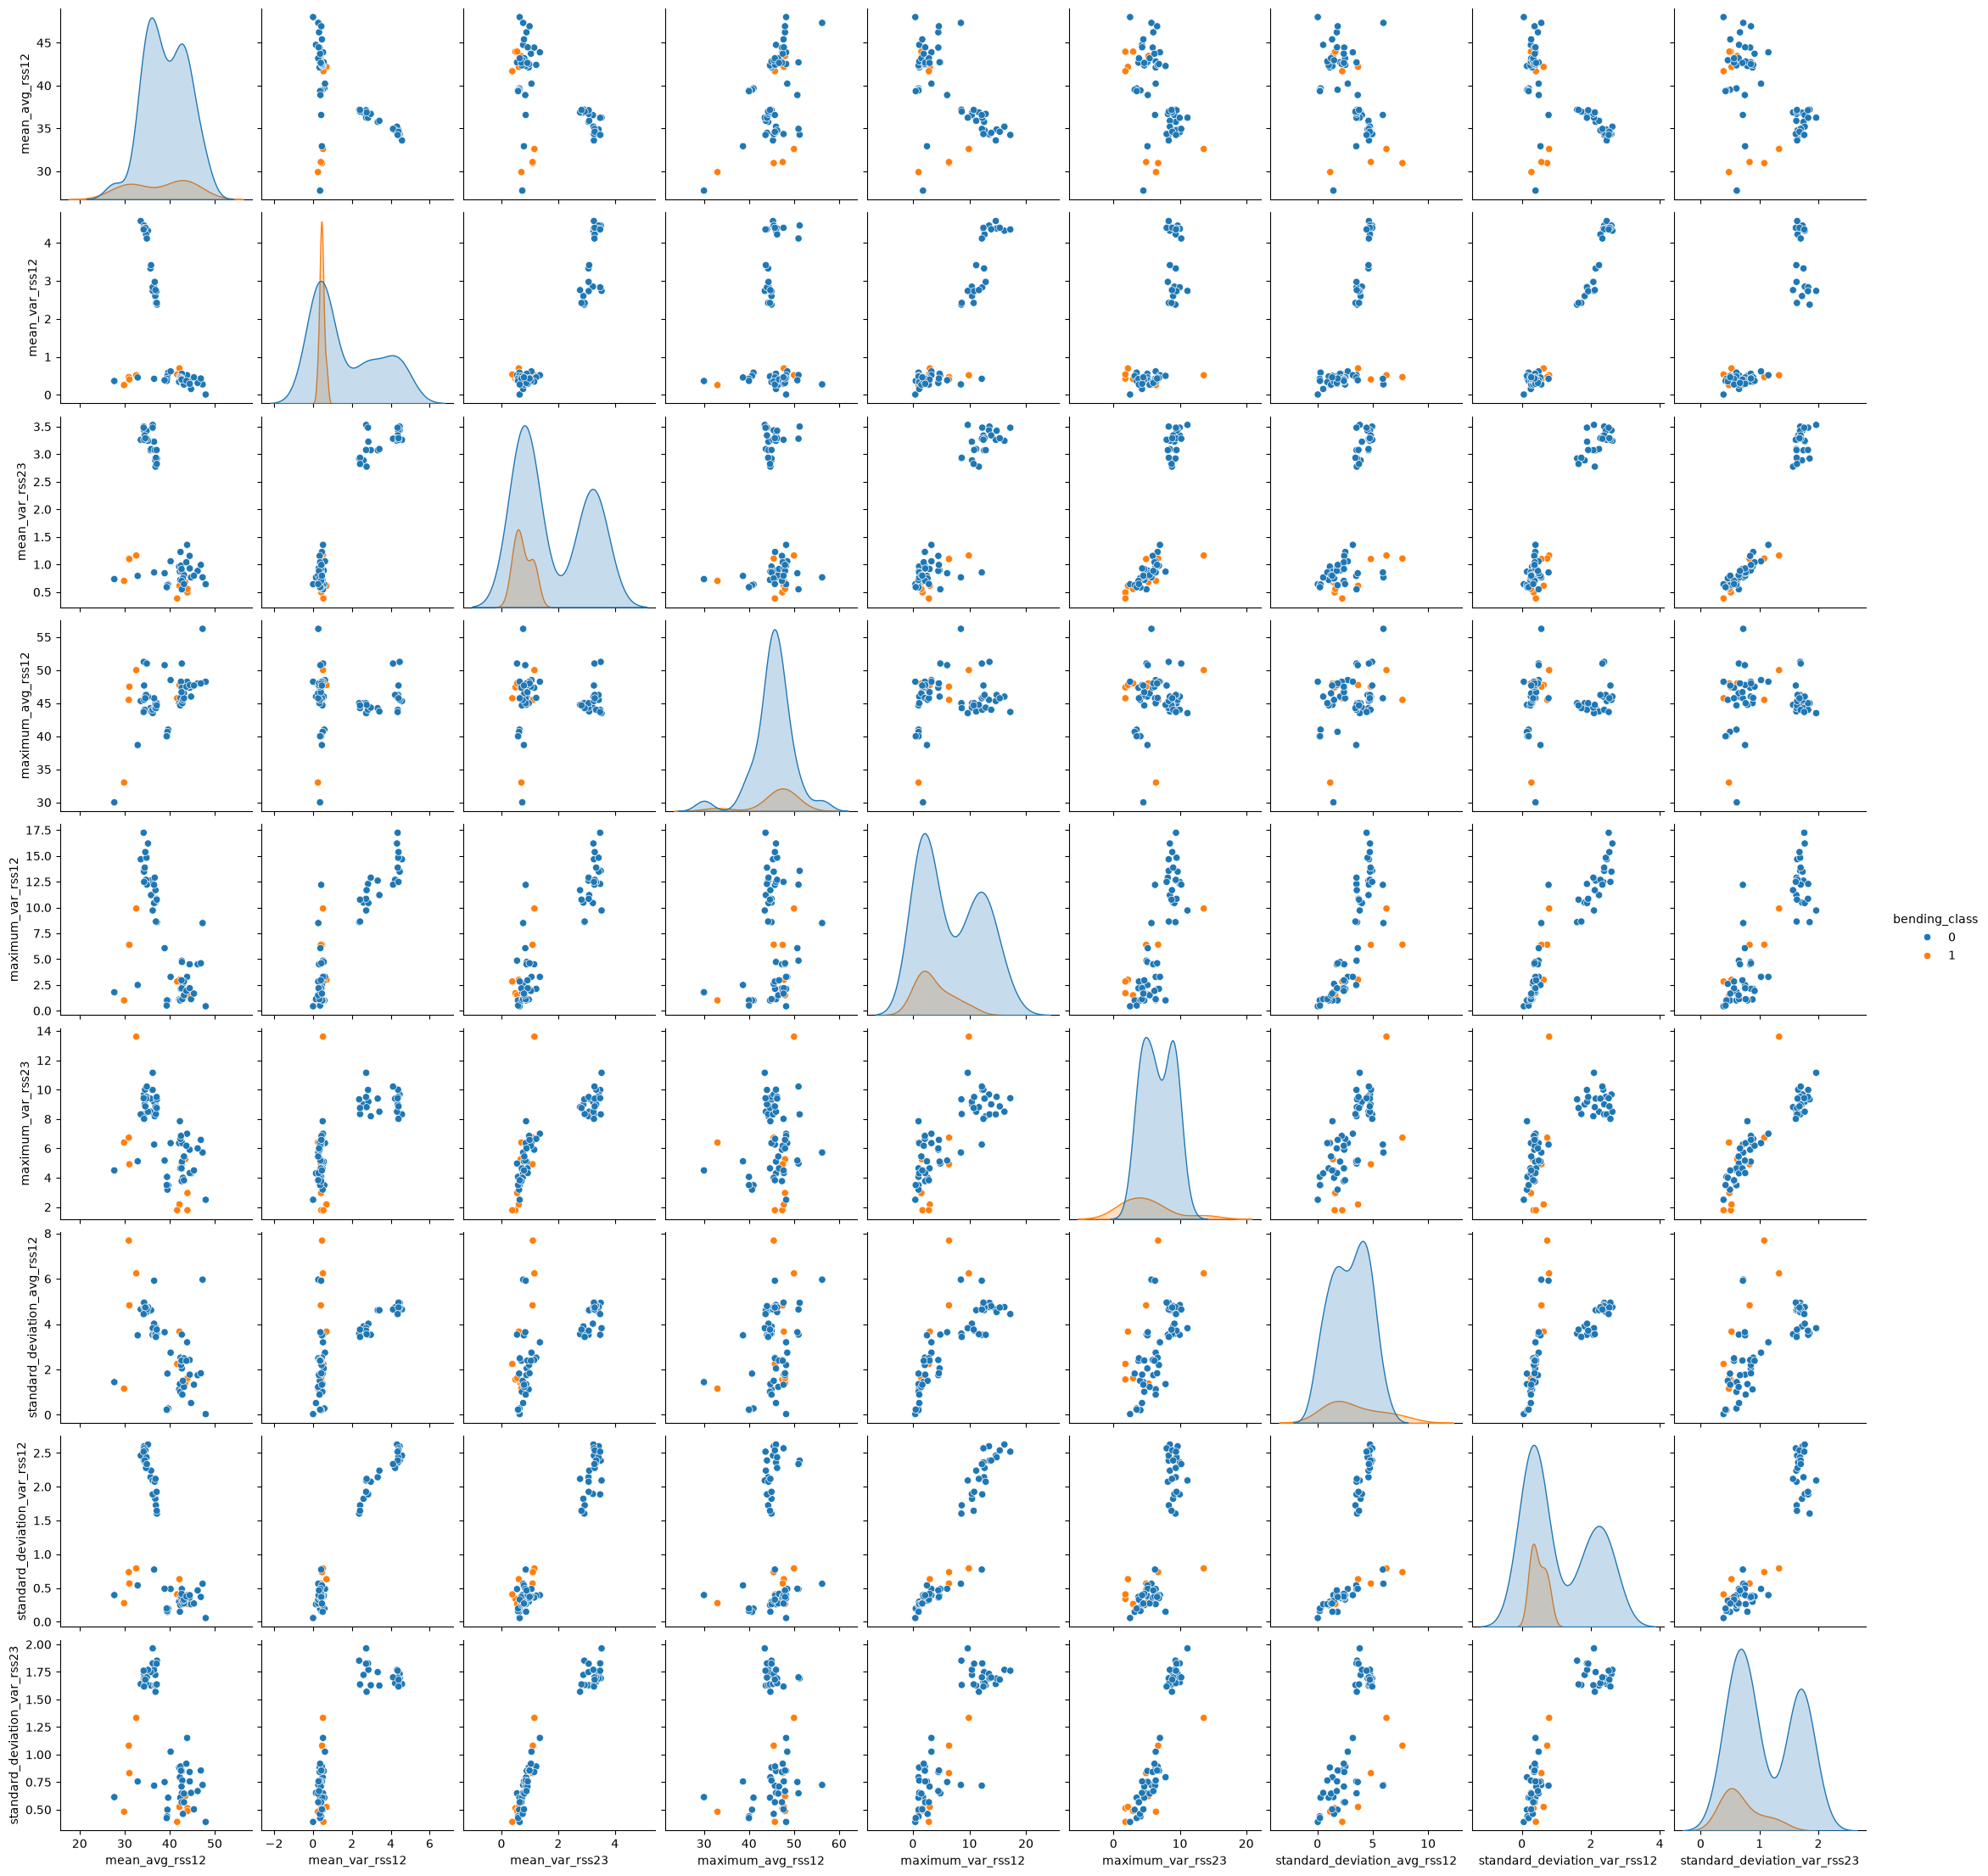

In [9]:
sns.pairplot(plot_data_2ai, hue='bending_class', vars=plot_data_2ai.columns.drop('bending_class'))
plt.show()

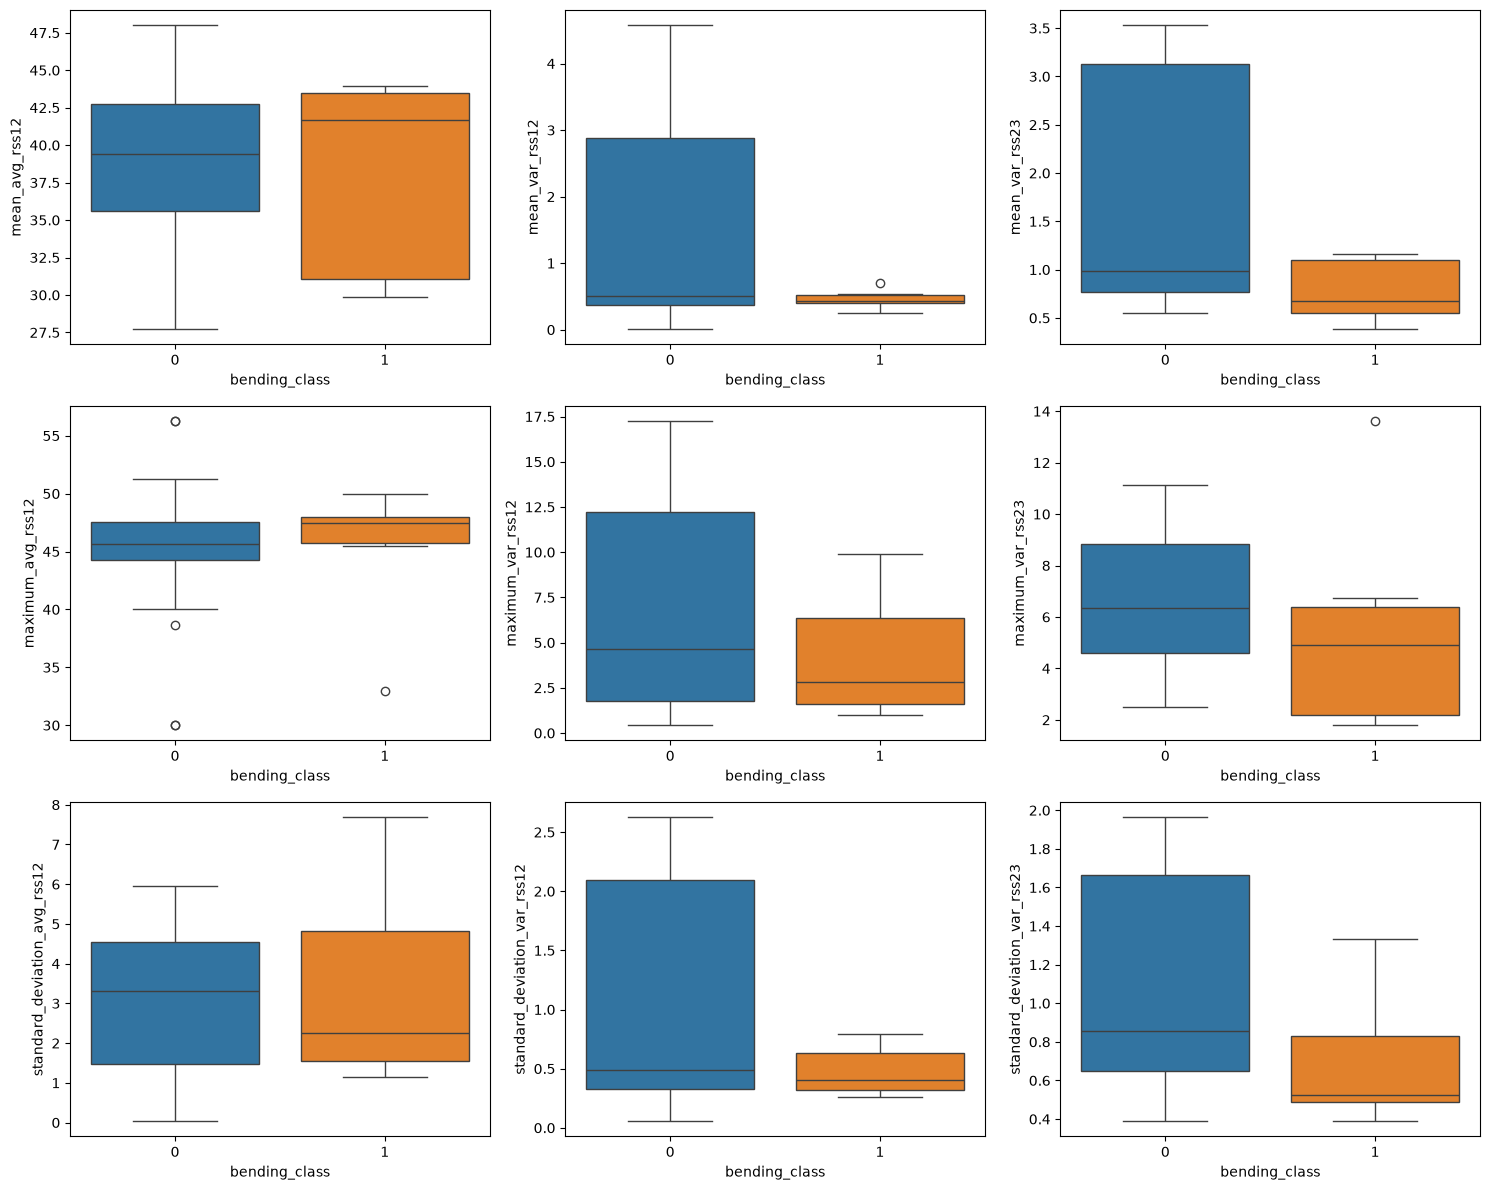

In [10]:
features_2ai = plot_data_2ai.columns.drop('bending_class')
figure_2ai, axes_2ai = plt.subplots(3, 3, figsize=(15, 12))
for feature, axis in zip(features_2ai, axes_2ai.flatten()):
    sns.boxplot(plot_data_2ai, x='bending_class', y=feature, hue='bending_class', legend=False, ax=axis)
plt.tight_layout()
plt.show()

#### ii. Splitted Plots

In [11]:
extracted_features_data_2_splits = extract_features(pd.concat([training_data, test_data], ignore_index=True), splits=2)
binary_classification_data_2_splits = extracted_features_data_2_splits.copy(deep=True)
binary_classification_data_2_splits.loc[
    binary_classification_data_2_splits['activity'] != 'bending', 'bending_class'] = 0
binary_classification_data_2_splits.loc[
    binary_classification_data_2_splits['activity'] == 'bending', 'bending_class'] = 1
binary_classification_data_2_splits['bending_class'] = binary_classification_data_2_splits['bending_class'].astype(int)
training_binary_classification_data_2_splits = binary_classification_data_2_splits[
    binary_classification_data_2_splits['is_training_data'] == True]
test_binary_classification_data_2_splits = binary_classification_data_2_splits[
    binary_classification_data_2_splits['is_training_data'] != True]
plot_columns_2aii = ['bending_class']
for statistic in ['mean', 'maximum', 'standard_deviation']:
    for time_series in ['avg_rss12', 'var_rss12', 'var_rss23']:
        for split_index in range(1, 3):
            plot_columns_2aii.append(f'{statistic}_{time_series}_{split_index}')
plot_data_2aii = training_binary_classification_data_2_splits[plot_columns_2aii]

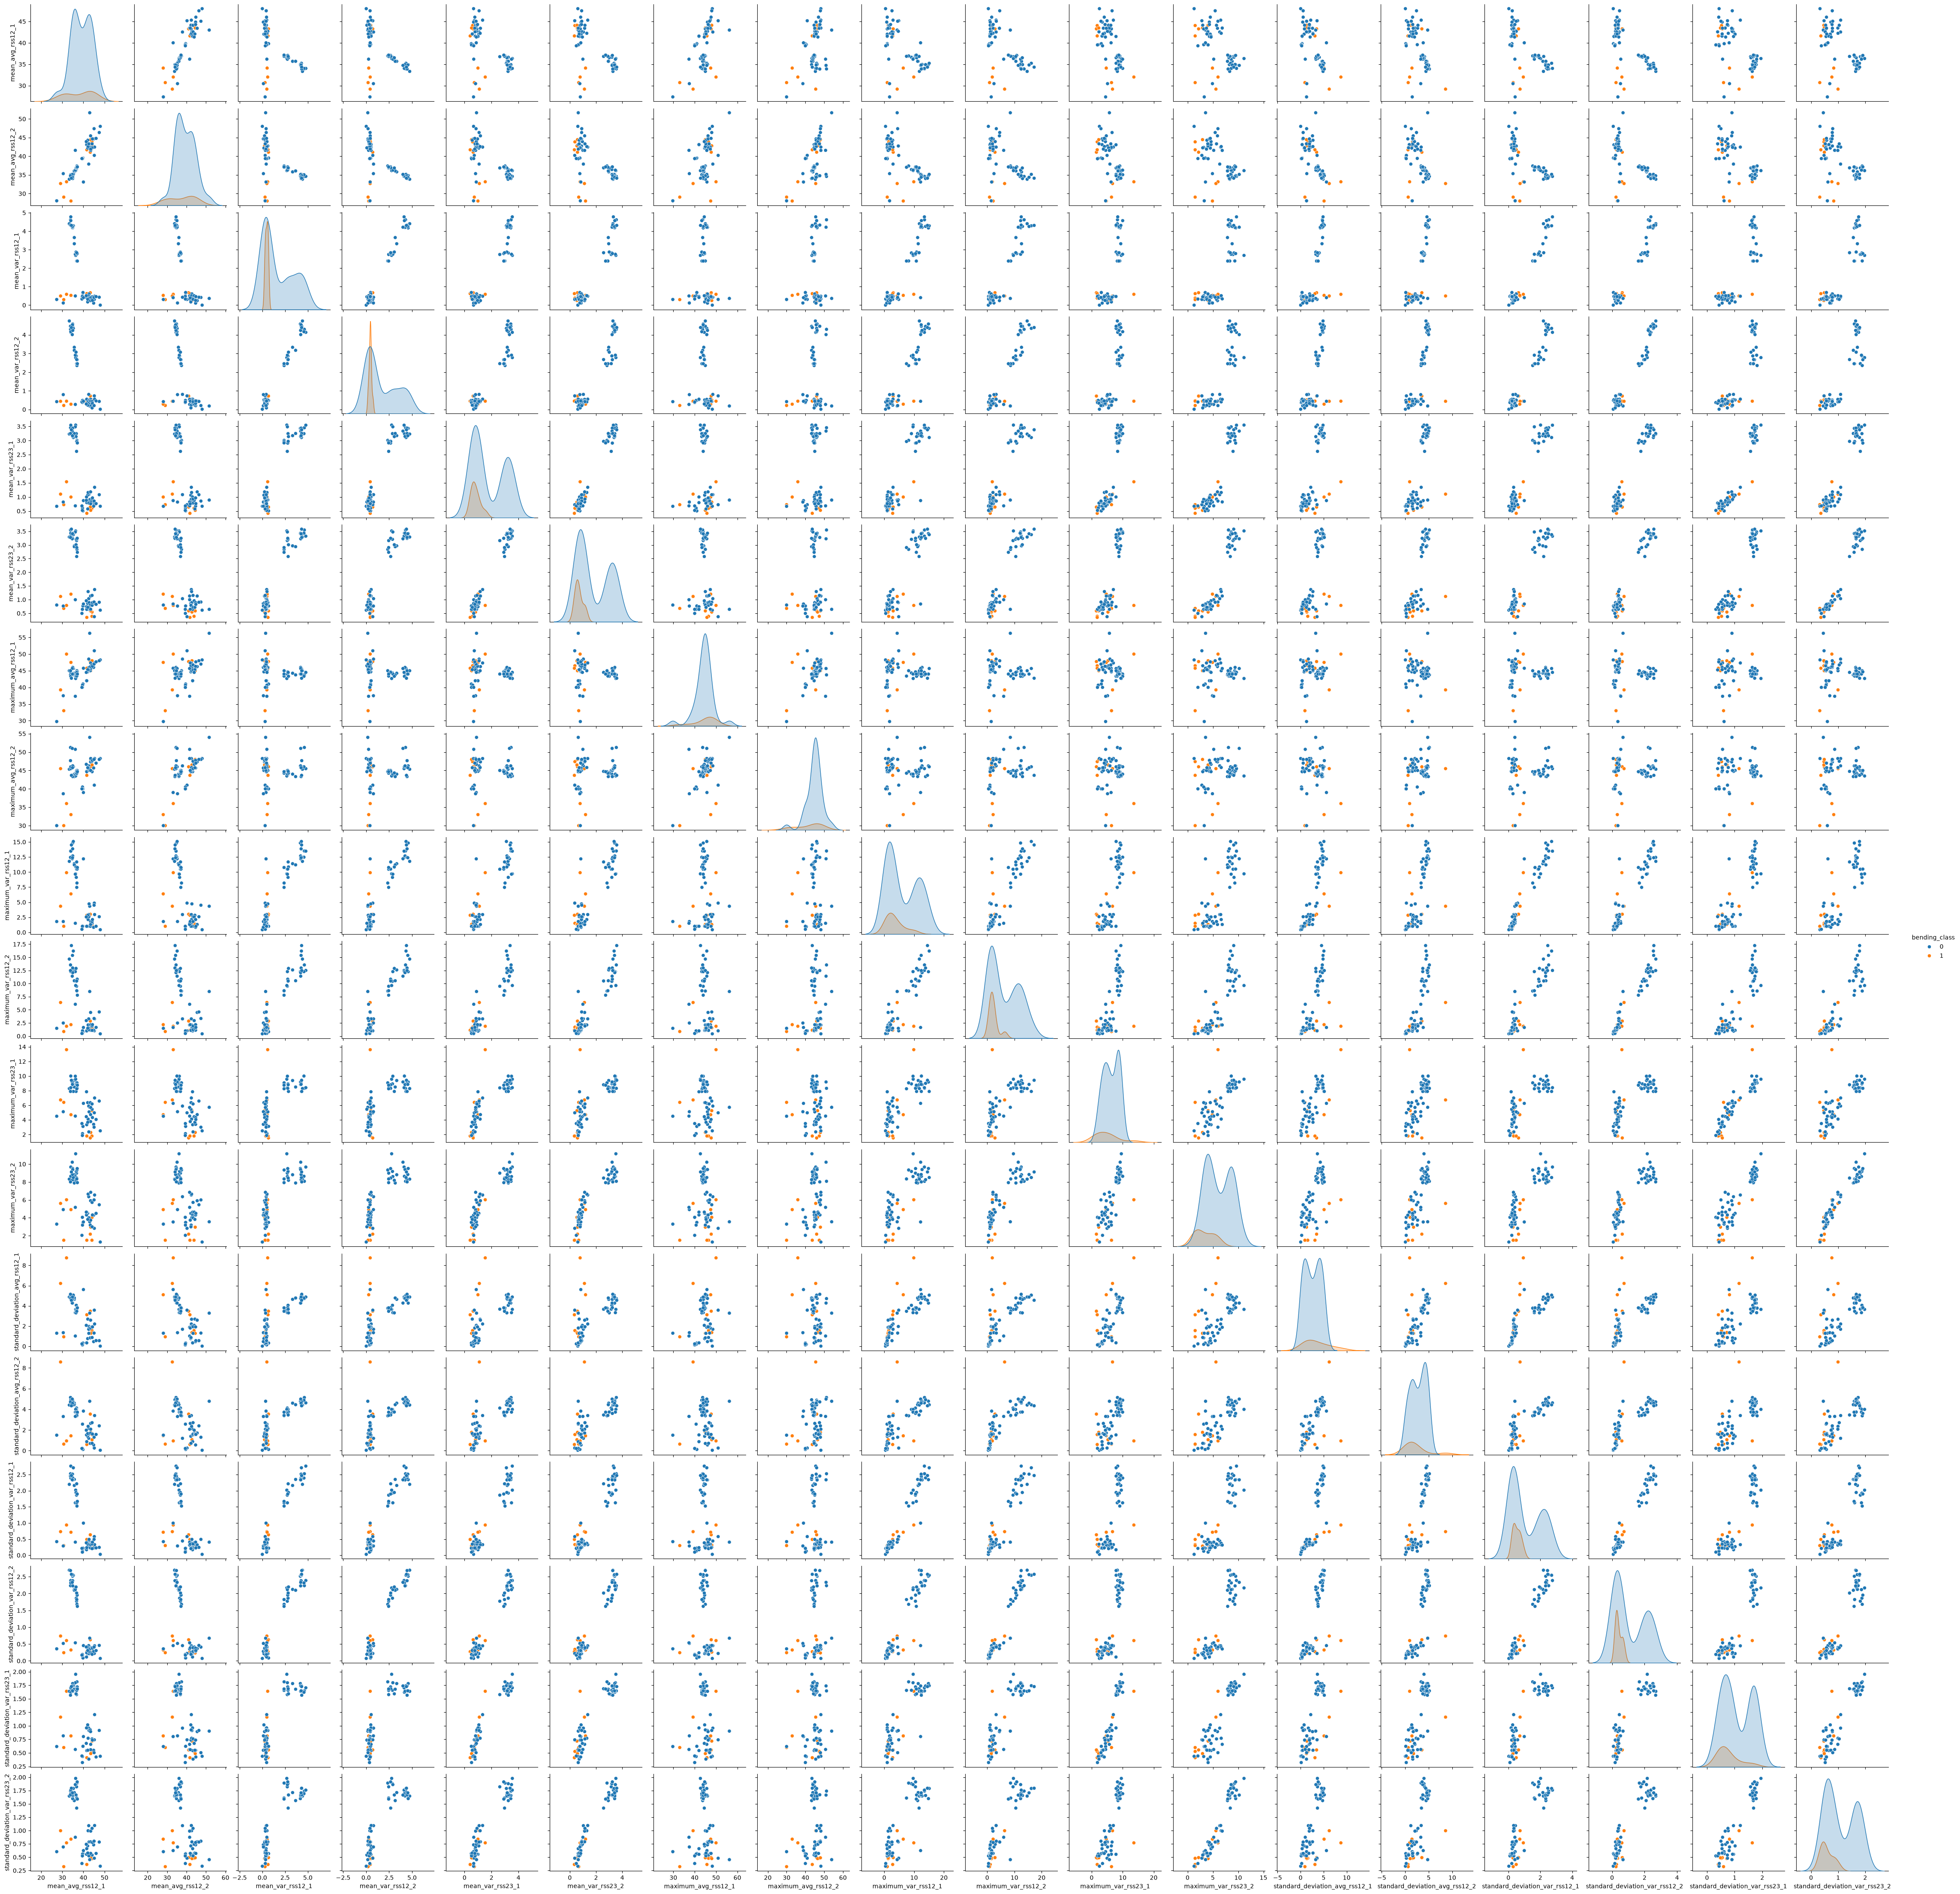

In [12]:
sns.pairplot(plot_data_2aii, hue='bending_class', vars=plot_data_2aii.columns.drop('bending_class'))
plt.show()

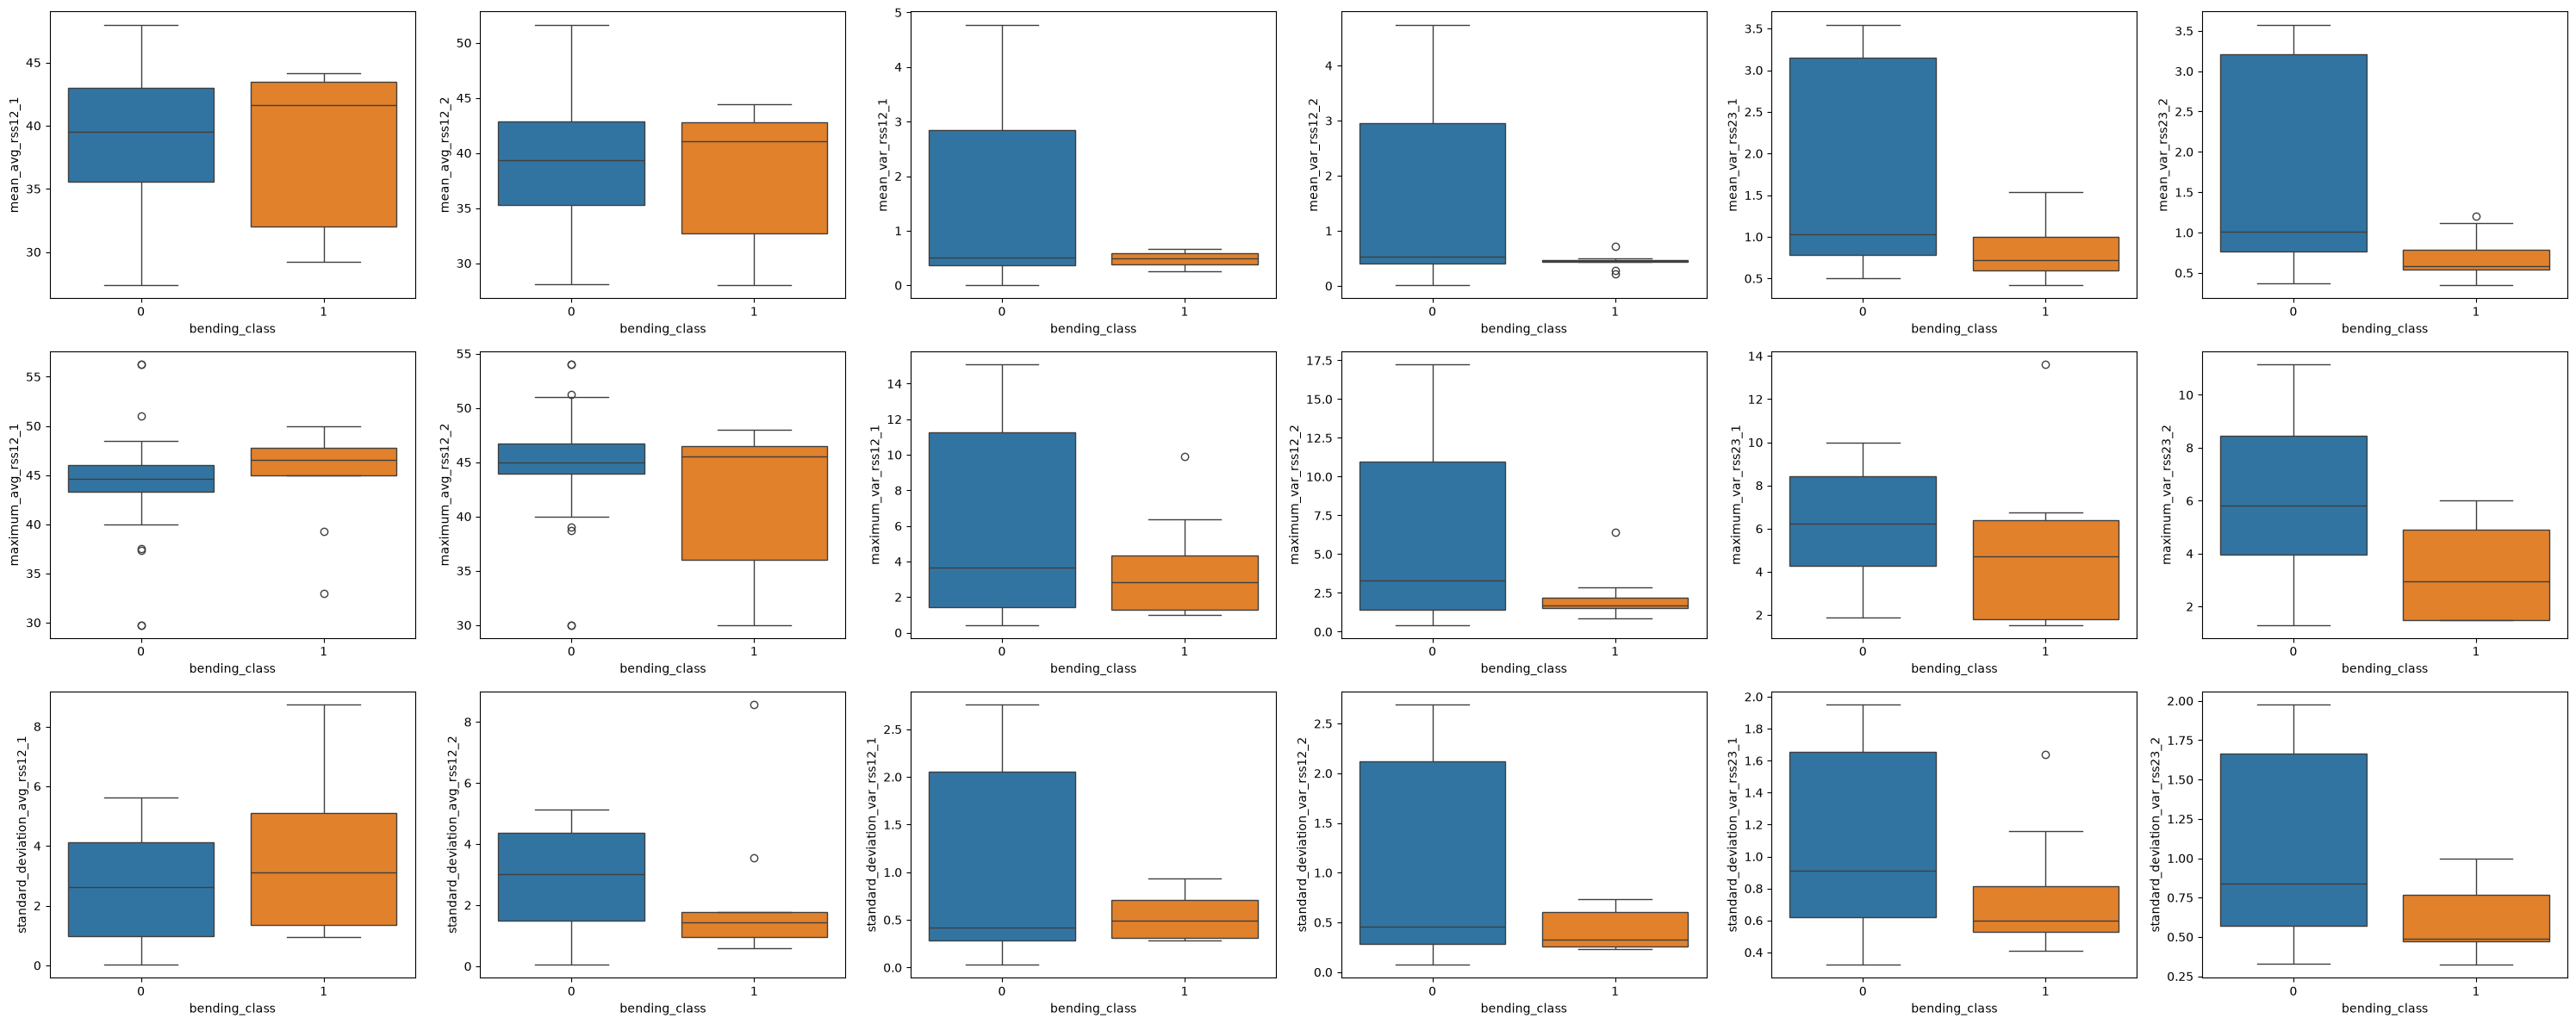

In [13]:
features_2aii = plot_data_2aii.columns.drop('bending_class')
figure_2aii, axes_2aii = plt.subplots(3, 6, figsize=(30, 12))
for feature, axis in zip(features_2aii, axes_2aii.flatten()):
    sns.boxplot(plot_data_2aii, x='bending_class', y=feature, hue='bending_class', legend=False, ax=axis)
plt.tight_layout()
plt.show()

**There is no considerable difference when going from one split to two.** The two half time series have approximately the same separation as the single time series.

#### iii. Time Series Segments

In [14]:
rfecv_results = []
for l in range(1, 21):
    binary_classification_data_l_splits_2aiii \
        = extract_features(pd.concat([training_data, test_data], ignore_index=True), splits=l)
    binary_classification_data_l_splits_2aiii.loc[
        binary_classification_data_l_splits_2aiii['activity'] != 'bending', 'bending_class'] = 0
    binary_classification_data_l_splits_2aiii.loc[
        binary_classification_data_l_splits_2aiii['activity'] == 'bending', 'bending_class'] = 1
    binary_classification_data_l_splits_2aiii['bending_class'] = binary_classification_data_l_splits_2aiii[
        'bending_class'].astype(
        int)
    training_binary_classification_data_l_splits_2aiii = binary_classification_data_l_splits_2aiii[
        binary_classification_data_l_splits_2aiii['is_training_data'] == True]
    test_binary_classification_data_l_splits_2aiii = binary_classification_data_l_splits_2aiii[
        binary_classification_data_l_splits_2aiii['is_training_data'] != True]
    feature_columns_2aiii = training_binary_classification_data_l_splits_2aiii.columns.drop(
        ['instance', 'is_training_data', 'activity', 'bending_class']).tolist()
    training_data_x_2aiii = training_binary_classification_data_l_splits_2aiii[feature_columns_2aiii]
    training_data_y_2aiii = training_binary_classification_data_l_splits_2aiii['bending_class']
    # C => infinity per footnote 3
    # max_iter => 100 is the default; tested with higher and lower values with no impact on CV accuracy
    rfecv = RFECV(make_pipeline(StandardScaler(), LogisticRegression(C=np.inf, max_iter=100, random_state=9999)),
                  step=1,
                  cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=9999),
                  scoring='accuracy',
                  # drop the feature with the lowest coefficient absolute value
                  importance_getter='named_steps.logisticregression.coef_')
    rfecv.fit(training_data_x_2aiii, training_data_y_2aiii)
    rfecv_results.append({'l': l,
                          'p': rfecv.n_features_,
                          'cross_validation_accuracy': rfecv.cv_results_['mean_test_score'].max(),
                          'selected_features': training_data_x_2aiii.columns[rfecv.support_].tolist()})
rfecv_results = pd.DataFrame(rfecv_results)

**Given the imbalanced dataset, I opted to use the `StratifiedKFold` approach with shuffling to ensure that each fold has a similar percentage of minority classes and a mixture of instances.**

This approach uses the 'right way' of cross-validation. That is, we divide the training dataset into `k=5` folds and hold out one of the folds for cross-validation accuracy. During cross-validation, RFE runs separately **within** each fold using only the `k-1` training folds, so the hold out fold never influences which features are kept. Selecting features on all training data first would evaluate models on data that trained them (and thus inflate accuracy). None of the `k` models trained see their respective held out fold during training. Also, at no point is any of the test data used for training or feature selection either because doing so could produce inflated test scores (i.e., better than if the data was truly unseen). We also only use the results of cross-validation for selecting `l` and `p`. No models trained during the cross-validation process are used or deployed.

In [15]:
display(rfecv_results)

,l,p,cross_validation_accuracy,selected_features
0,1,14,1.000000,"[minimum_avg_rss12, maximum_avg_rss12, mean_av..."
1,2,18,0.971429,"[median_avg_rss12_1, standard_deviation_avg_rs..."
2,3,5,0.957143,"[first_quartile_avg_rss12_1, maximum_var_rss12..."
3,4,13,0.942857,"[maximum_avg_rss23_1, mean_avg_rss23_1, first_..."
4,5,173,0.957143,"[minimum_avg_rss12_1, maximum_avg_rss12_1, mea..."
5,6,13,0.957143,"[maximum_avg_rss23_1, mean_avg_rss23_1, third_..."
6,7,10,0.942857,"[minimum_avg_rss23_1, maximum_avg_rss23_1, min..."
7,8,4,0.971429,"[maximum_avg_rss23_2, standard_deviation_avg_r..."
8,9,3,0.970330,"[mean_avg_rss23_2, median_var_rss13_7, minimum..."
9,10,9,0.957143,"[maximum_avg_rss23_1, mean_avg_rss23_2, third_..."


In [16]:
best_result = rfecv_results.loc[rfecv_results['cross_validation_accuracy'].idxmax()]
display(f'Best l: {best_result["l"]}')
display(f'Best p: {best_result["p"]}')
display(f'Best cross validation accuracy: {best_result["cross_validation_accuracy"]}')
display(f'Selected features: {best_result["selected_features"]}')

'Best l: 1'

'Best p: 14'

'Best cross validation accuracy: 1.0'

"Selected features: ['minimum_avg_rss12', 'maximum_avg_rss12', 'mean_avg_rss12', 'third_quartile_avg_rss12', 'maximum_var_rss12', 'third_quartile_avg_rss13', 'maximum_var_rss13', 'first_quartile_var_rss13', 'minimum_avg_rss23', 'maximum_avg_rss23', 'mean_avg_rss23', 'first_quartile_avg_rss23', 'standard_deviation_var_rss23', 'first_quartile_var_rss23']"

In [17]:
best_l_2aiii = int(best_result['l'])
best_selected_features = best_result['selected_features']
best_l_data = extract_features(pd.concat([training_data, test_data], ignore_index=True), splits=best_l_2aiii)
best_l_data.loc[best_l_data['activity'] != 'bending', 'bending_class'] = 0
best_l_data.loc[best_l_data['activity'] == 'bending', 'bending_class'] = 1
best_l_data['bending_class'] = best_l_data['bending_class'].astype(int)
best_l_training_data = best_l_data[best_l_data['is_training_data'] == True]
best_l_test_data = best_l_data[best_l_data['is_training_data'] != True]
standard_scaler_2aiii = StandardScaler().fit(best_l_training_data[best_selected_features])
training_data_x_2aiii = sm.add_constant(
    pd.DataFrame(standard_scaler_2aiii.transform(best_l_training_data[best_selected_features]),
                 columns=best_selected_features, index=best_l_training_data.index))
training_data_y_2aiii = best_l_training_data['bending_class']
logit_training_result_2aiii = sm.Logit(training_data_y_2aiii, training_data_x_2aiii).fit(maxiter=100)

         Current function value: 0.000000
         Iterations: 100


/opt/homebrew/Cellar/jupyterlab/4.6.4_2/libexec/lib/python3.15/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/opt/homebrew/Cellar/jupyterlab/4.6.4_2/libexec/lib/python3.15/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/opt/homebrew/Cellar/jupyterlab/4.6.4_2/libexec/lib/python3.15/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/opt/homebrew/Cellar/jupyterlab/4.6.4_2/libexec/lib/python3.15/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/opt/homebrew/Cellar/jupyterlab/4.6.4_2/libexec/lib/python3.

#### iv. Confusion Matrix

In [18]:
training_probabilities_2aiv = logit_training_result_2aiii.predict(training_data_x_2aiii)
training_classifications_2aiv = (training_probabilities_2aiv >= 0.5).astype(int)

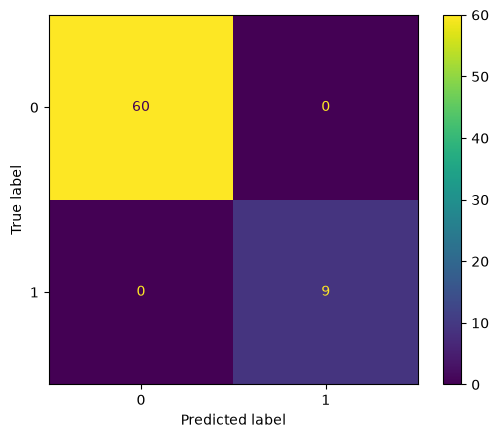

In [19]:
ConfusionMatrixDisplay.from_predictions(training_data_y_2aiii, training_classifications_2aiv)
plt.show()

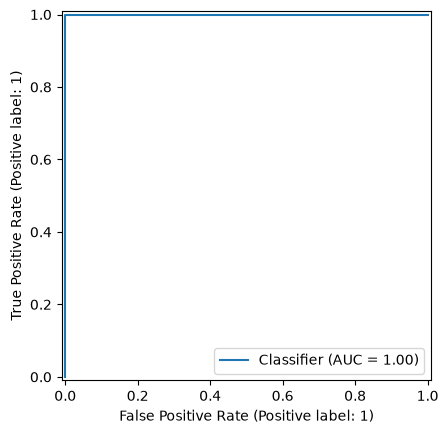

In [20]:
RocCurveDisplay.from_predictions(training_data_y_2aiii, training_probabilities_2aiv)
plt.show()

In [21]:
print(f'Training AUC: {roc_auc_score(training_data_y_2aiii, training_probabilities_2aiv)}')

Training AUC: 1.0


In [22]:
display(
    pd.DataFrame({'coefficient': logit_training_result_2aiii.params, 'p_value': logit_training_result_2aiii.pvalues}))

,coefficient,p_value
const,-31.349988,0.999855
minimum_avg_rss12,-7.907366,0.999972
maximum_avg_rss12,8.264291,0.999980
mean_avg_rss12,6.759289,0.999996
third_quartile_avg_rss12,-19.744071,0.999985
maximum_var_rss12,-8.800355,0.999989
third_quartile_avg_rss13,-0.197185,1.000000
maximum_var_rss13,10.362747,0.999977
first_quartile_var_rss13,-14.071806,0.999994
minimum_avg_rss23,20.954043,0.999971


#### v. Test Classifier

Cross-validation accuracy: 1.000
Test accuracy: 1.0


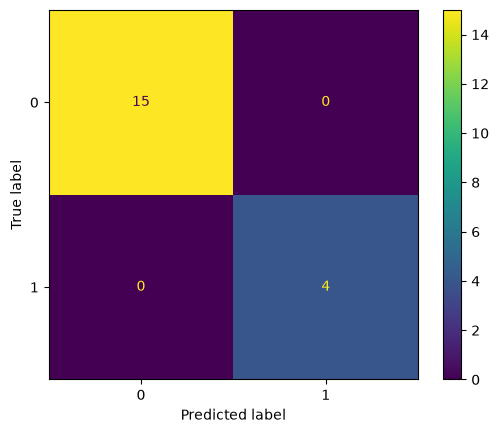

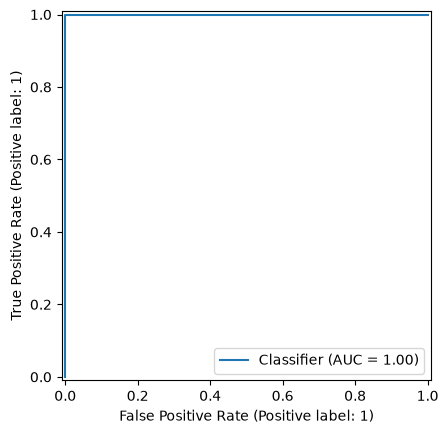

Test ROC AUC: 1.0


In [23]:
test_data_x_2av = sm.add_constant(
    pd.DataFrame(standard_scaler_2aiii.transform(best_l_test_data[best_selected_features]),
                 columns=best_selected_features, index=best_l_test_data.index))
test_data_y_2av = best_l_test_data['bending_class'].astype(int)
test_probabilities_2av = logit_training_result_2aiii.predict(test_data_x_2av)
test_predictions_2av = (test_probabilities_2av >= 0.5).astype(int)
test_accuracy_2av = accuracy_score(test_data_y_2av, test_predictions_2av)
print(f"Cross-validation accuracy: {best_result['cross_validation_accuracy']:.3f}")
print(f'Test accuracy: {test_accuracy_2av}')
ConfusionMatrixDisplay.from_predictions(test_data_y_2av, test_predictions_2av)
plt.show()
RocCurveDisplay.from_predictions(test_data_y_2av, test_probabilities_2av)
plt.show()
print(f'Test ROC AUC: {roc_auc_score(test_data_y_2av, test_probabilities_2av)}')

Both the test and training results have perfect accuracy and ROC AUC. This matches the perfect CV accuracy for `l=1`/`p=14` as well.

#### vi. Separation

There is ample evidence of well-separated classes causing instability. First, `statsmodels` threw numerous `PerfectSeparationWarning`s when training the logistic regression model (and training only stopped due to the 100 iteration limit). The training data has perfect accuracy (see confusion matrices) and ROC AUC. Finally, the feature p-values are all close to 1.0.

#### vii. Imbalance

Yes, there is clearly class imbalance. In the training data, there are 60 negative to 9 positive class instances. In the test data, there are 15 negative to 4 positive class instances.

In [24]:
case_indexes = training_data_y_2aiii[training_data_y_2aiii == 1].index
control_indexes = training_data_y_2aiii[training_data_y_2aiii == 0].sample(n=len(case_indexes), random_state=9999).index
case_control_indexes = case_indexes.union(control_indexes)
case_control_x = training_data_x_2aiii.loc[case_control_indexes]
case_control_y = training_data_y_2aiii.loc[case_control_indexes]
logit_training_result_2avii = sm.Logit(case_control_y, case_control_x).fit(maxiter=100)
total_bending_proportion = training_data_y_2aiii.mean()
sample_bending_proportion = case_control_y.mean()
adjusted_params_2avii = logit_training_result_2avii.params.copy()
adjusted_params_2avii['const'] += np.log(total_bending_proportion / (1 - total_bending_proportion)) - np.log(
    sample_bending_proportion / (1 - sample_bending_proportion))
display(pd.DataFrame({'case_control': logit_training_result_2avii.params, 'adjusted': adjusted_params_2avii}))

         Current function value: 0.000000
         Iterations: 100


/opt/homebrew/Cellar/jupyterlab/4.6.4_2/libexec/lib/python3.15/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/opt/homebrew/Cellar/jupyterlab/4.6.4_2/libexec/lib/python3.15/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/opt/homebrew/Cellar/jupyterlab/4.6.4_2/libexec/lib/python3.15/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/opt/homebrew/Cellar/jupyterlab/4.6.4_2/libexec/lib/python3.15/site-packages/statsmodels/base/optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
/opt/homebrew/Cellar/jupyterlab/4.6.4_2/libexec/lib/python3.

,case_control,adjusted
const,-14.265903,-16.163023
minimum_avg_rss12,-19.992735,-19.992735
maximum_avg_rss12,2.628538,2.628538
mean_avg_rss12,10.927945,10.927945
third_quartile_avg_rss12,-15.416631,-15.416631
maximum_var_rss12,-16.508703,-16.508703
third_quartile_avg_rss13,-1.704450,-1.704450
maximum_var_rss13,6.358560,6.358560
first_quartile_var_rss13,21.902259,21.902259
minimum_avg_rss23,9.564427,9.564427


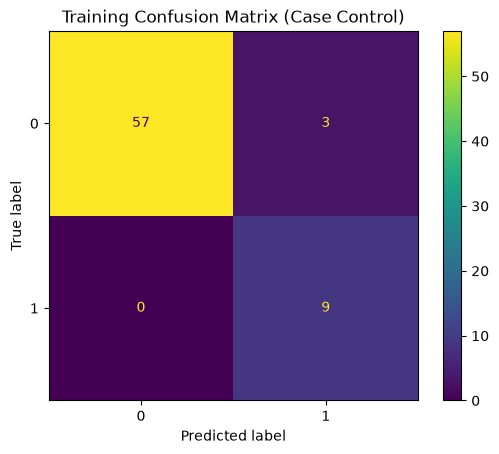

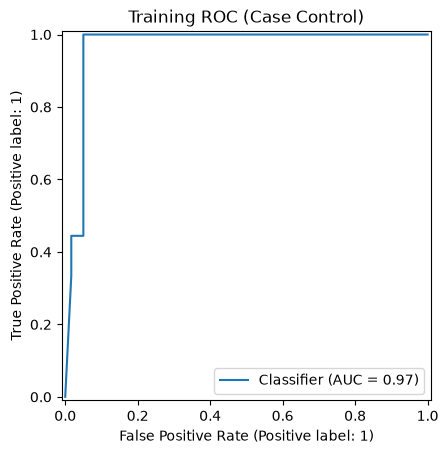

Training AUC: 0.9675925925925927


In [25]:
training_predictions_2avii = logit_training_result_2avii.model.predict(adjusted_params_2avii, training_data_x_2aiii)
training_classifications_2avii = (training_predictions_2avii >= 0.5).astype(int)
ConfusionMatrixDisplay.from_predictions(training_data_y_2aiii, training_classifications_2avii)
plt.title('Training Confusion Matrix (Case Control)')
plt.show()
RocCurveDisplay.from_predictions(training_data_y_2aiii, training_predictions_2avii)
plt.title('Training ROC (Case Control)')
plt.show()
print(f'Training AUC: {roc_auc_score(training_data_y_2aiii, training_predictions_2avii)}')

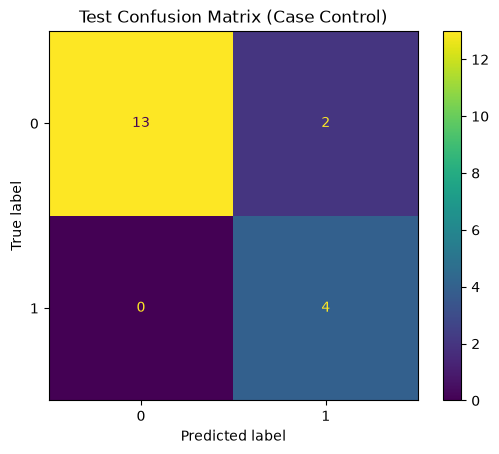

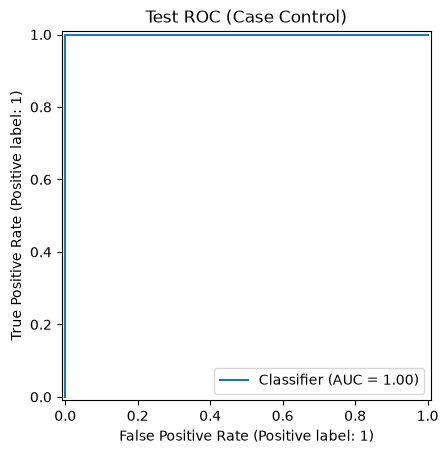

Test AUC: 1.0


In [26]:
test_predictions_2avii = logit_training_result_2avii.model.predict(adjusted_params_2avii, test_data_x_2av)
test_classifications_2avii = (test_predictions_2avii >= 0.5).astype(int)
ConfusionMatrixDisplay.from_predictions(test_data_y_2av, test_classifications_2avii)
plt.title('Test Confusion Matrix (Case Control)')
plt.show()
RocCurveDisplay.from_predictions(test_data_y_2av, test_predictions_2avii)
plt.title('Test ROC (Case Control)')
plt.show()
print(f'Test AUC: {roc_auc_score(test_data_y_2av, test_predictions_2avii)}')

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [27]:
grid_search_results = []
for l in range(1, 21):
    binary_classification_data_l_splits_2bi \
        = extract_features(pd.concat([training_data, test_data], ignore_index=True), splits=l)
    binary_classification_data_l_splits_2bi.loc[
        binary_classification_data_l_splits_2bi['activity'] != 'bending', 'bending_class'] = 0
    binary_classification_data_l_splits_2bi.loc[
        binary_classification_data_l_splits_2bi['activity'] == 'bending', 'bending_class'] = 1
    binary_classification_data_l_splits_2bi['bending_class'] = binary_classification_data_l_splits_2bi[
        'bending_class'].astype(
        int)
    training_binary_classification_data_l_splits_2bi = binary_classification_data_l_splits_2bi[
        binary_classification_data_l_splits_2bi['is_training_data'] == True]
    test_binary_classification_data_l_splits_2bi = binary_classification_data_l_splits_2bi[
        binary_classification_data_l_splits_2bi['is_training_data'] != True]
    feature_columns_2bi = training_binary_classification_data_l_splits_2bi.columns.drop(
        ['instance', 'is_training_data', 'activity', 'bending_class']).tolist()
    training_data_x_2bi = training_binary_classification_data_l_splits_2bi[feature_columns_2bi]
    training_data_y_2bi = training_binary_classification_data_l_splits_2bi['bending_class']
    # default solver lbfgs does not support L1 regularization
    grid_search = GridSearchCV(
        make_pipeline(StandardScaler(), LogisticRegression(l1_ratio=1.0, solver='liblinear', random_state=9999)),
        param_grid={'logisticregression__C': np.logspace(-10, 10, 50, base=10)},
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=9999),
        scoring='accuracy')
    grid_search.fit(training_data_x_2bi, training_data_y_2bi)
    best_coefficients = grid_search.best_estimator_.named_steps['logisticregression'].coef_[0]
    grid_search_results.append({'l': l,
                                'C': grid_search.best_params_['logisticregression__C'],
                                'p': int((best_coefficients != 0).sum()),
                                'cross_validation_accuracy': grid_search.best_score_,
                                'selected_features': training_data_x_2bi.columns[best_coefficients != 0].tolist()})
grid_search_results = pd.DataFrame(grid_search_results)

In [28]:
display(grid_search_results)

,l,C,p,cross_validation_accuracy,selected_features
0,1,449.843267,16,0.985714,"[minimum_avg_rss12, maximum_avg_rss12, third_q..."
1,2,10.481131,11,0.971429,"[median_avg_rss12_1, maximum_var_rss12_1, stan..."
2,3,0.244205,5,0.970330,"[minimum_avg_rss23_1, maximum_avg_rss23_1, fir..."
3,4,7543.120063,111,0.942857,"[minimum_avg_rss12_1, mean_avg_rss12_1, median..."
4,5,2947.051703,84,0.942857,"[minimum_avg_rss12_1, mean_avg_rss12_1, median..."
5,6,828642.772855,252,0.957143,"[minimum_avg_rss12_1, maximum_avg_rss12_1, mea..."
6,7,68.664885,25,0.957143,"[third_quartile_avg_rss12_1, minimum_avg_rss23..."
7,8,175.751062,37,0.971429,"[median_avg_rss12_1, third_quartile_avg_rss12_..."
8,9,4.094915,14,0.942857,"[maximum_avg_rss23_1, standard_deviation_avg_r..."
9,10,175.751062,34,0.957143,"[third_quartile_avg_rss12_1, maximum_avg_rss23..."


In [29]:
best_grid_search_result = grid_search_results.loc[grid_search_results['cross_validation_accuracy'].idxmax()]
display(f'Best l: {best_grid_search_result["l"]}')
display(f'Best C: {best_grid_search_result["C"]}')
display(f'Best p: {best_grid_search_result["p"]}')
display(f'Best cross validation accuracy: {best_grid_search_result["cross_validation_accuracy"]}')
display(f'Selected features: {best_grid_search_result["selected_features"]}')

'Best l: 1'

'Best C: 449.8432668969453'

'Best p: 16'

'Best cross validation accuracy: 0.9857142857142858'

"Selected features: ['minimum_avg_rss12', 'maximum_avg_rss12', 'third_quartile_avg_rss12', 'maximum_var_rss12', 'minimum_avg_rss13', 'median_avg_rss13', 'third_quartile_avg_rss13', 'maximum_var_rss13', 'median_var_rss13', 'first_quartile_var_rss13', 'minimum_avg_rss23', 'maximum_avg_rss23', 'mean_avg_rss23', 'median_var_rss23', 'standard_deviation_var_rss23', 'first_quartile_var_rss23']"

In [30]:
best_l_2bi = int(best_grid_search_result['l'])
best_C = best_grid_search_result['C']
best_lC_data = extract_features(pd.concat([training_data, test_data], ignore_index=True), splits=best_l_2bi)
best_lC_data.loc[best_lC_data['activity'] == 'bending', 'bending_class'] = 1
best_lC_data.loc[best_lC_data['activity'] != 'bending', 'bending_class'] = 0
best_lC_data['bending_class'] = best_lC_data['bending_class'].astype(int)
best_lC_training_data = best_lC_data[best_lC_data['is_training_data'] == True]
best_lC_test_data = best_lC_data[best_lC_data['is_training_data'] != True]
feature_columns_2bi = best_lC_training_data.columns.drop(
    ['instance', 'is_training_data', 'activity', 'bending_class']).tolist()
training_data_x_2bi = best_lC_training_data[feature_columns_2bi]
training_data_y_2bi = best_lC_training_data['bending_class']
l1_pipeline_2bi = make_pipeline(StandardScaler(),
                                LogisticRegression(l1_ratio=1.0, solver='liblinear', C=best_C, random_state=9999))
l1_pipeline_2bi.fit(training_data_x_2bi, training_data_y_2bi)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](42,)","['minimum_avg_rss12','maximum_avg_rss12','mean_avg_rss12',..., 'standard_deviation_var_rss23','first_quartile_var_rss23', 'third_quartile_var_rss23']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,42
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [31]:
training_probabilities_2bi = l1_pipeline_2bi.predict_proba(training_data_x_2bi)[:, 1]
training_classifications_2bi = (training_probabilities_2bi >= 0.5).astype(int)

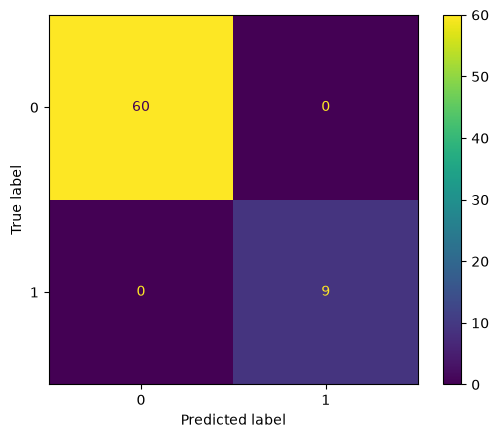

In [32]:
ConfusionMatrixDisplay.from_predictions(training_data_y_2bi, training_classifications_2bi)
plt.show()

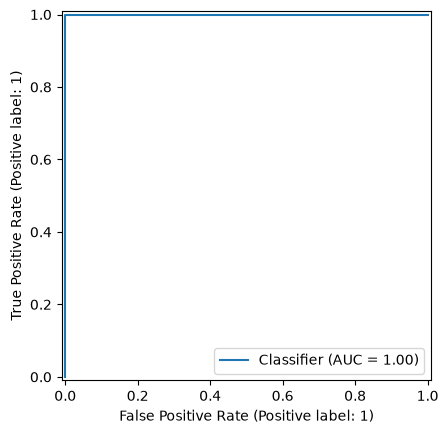

In [33]:
RocCurveDisplay.from_predictions(training_data_y_2bi, training_probabilities_2bi)
plt.show()

In [34]:
print(f'Training AUC: {roc_auc_score(training_data_y_2bi, training_probabilities_2bi)}')

Training AUC: 1.0


In [35]:
l1_coefficients_2bi = pd.Series(l1_pipeline_2bi.named_steps['logisticregression'].coef_[0], index=feature_columns_2bi)
display(f"Intercept: {l1_pipeline_2bi.named_steps['logisticregression'].intercept_[0]}")
display(pd.DataFrame({'coefficient': l1_coefficients_2bi[l1_coefficients_2bi != 0]}))

'Intercept: -10.583661359168433'

,coefficient
minimum_avg_rss12,-1.658785
maximum_avg_rss12,0.379117
third_quartile_avg_rss12,-2.526961
maximum_var_rss12,-1.636379
minimum_avg_rss13,-0.075136
median_avg_rss13,-0.396000
third_quartile_avg_rss13,-0.914998
maximum_var_rss13,1.437357
median_var_rss13,-0.226733
first_quartile_var_rss13,-1.764916


Cross-validation accuracy: 0.986
Test accuracy: 1.0


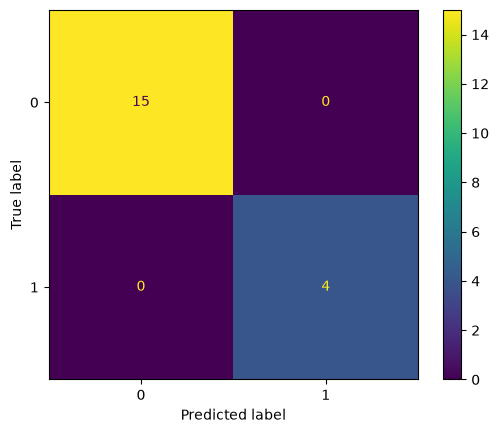

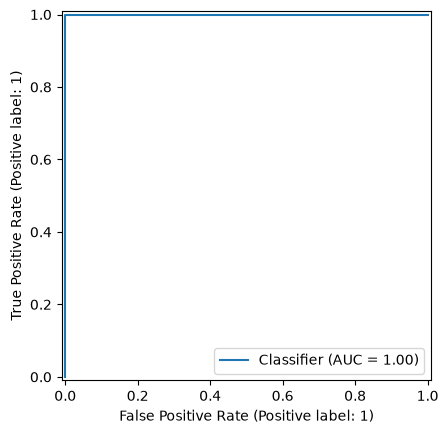

Test ROC AUC: 1.0


In [36]:
test_data_x_2bi = best_lC_test_data[feature_columns_2bi]
test_data_y_2bi = best_lC_test_data['bending_class']
test_probabilities_2bi = l1_pipeline_2bi.predict_proba(test_data_x_2bi)[:, 1]
test_predictions_2bi = (test_probabilities_2bi >= 0.5).astype(int)
test_accuracy_2bi = accuracy_score(test_data_y_2bi, test_predictions_2bi)
print(f"Cross-validation accuracy: {best_grid_search_result['cross_validation_accuracy']:.3f}")
print(f'Test accuracy: {test_accuracy_2bi}')
ConfusionMatrixDisplay.from_predictions(test_data_y_2bi, test_predictions_2bi)
plt.show()
RocCurveDisplay.from_predictions(test_data_y_2bi, test_probabilities_2bi)
plt.show()
print(f'Test ROC AUC: {roc_auc_score(test_data_y_2bi, test_probabilities_2bi)}')

#### ii. Comparison

From a test dataset accuracy perspective, RFECV (1.0) and L1 logistic regression (1.0) are tied. RFECV has slightly better cross validation accuracy (1.0 versus 0.986). RFECV kept 14 features versus 16 for L1 logistic regression. The RFECV coefficients are larger (absolute value max of 21.0) versus L1 logistic regression (absolute value max of 5.6). L1 logistic regression is the better choice due to the fact that the penalization forces convergence (whereas the other approach only stops due to a cap on iterations). From an implementation perspective, L1 logistic regression was easier because it doesn't require a separate `statsmodels` import just to get p-values.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

In [37]:
grid_search_results_2ci = []
for l in range(1, 21):
    multinomial_classification_data_l_splits_2ci \
        = extract_features(pd.concat([training_data, test_data], ignore_index=True), splits=l)
    training_multinomial_classification_data_l_splits_2ci = multinomial_classification_data_l_splits_2ci[
        multinomial_classification_data_l_splits_2ci['is_training_data'] == True]
    test_multinomial_classification_data_l_splits_2ci = multinomial_classification_data_l_splits_2ci[
        multinomial_classification_data_l_splits_2ci['is_training_data'] != True]
    feature_columns_2ci = training_multinomial_classification_data_l_splits_2ci.columns.drop(
        ['instance', 'is_training_data', 'activity']).tolist()
    training_data_x_2ci = training_multinomial_classification_data_l_splits_2ci[feature_columns_2ci]
    training_data_y_2ci = training_multinomial_classification_data_l_splits_2ci['activity']
    # liblinear does not support multi-class; using saga as a solver instead
    grid_search_2ci = GridSearchCV(make_pipeline(StandardScaler(),
                                                 LogisticRegression(l1_ratio=1.0, solver='saga', max_iter=5000,
                                                                    random_state=9999)),
                                   param_grid={'logisticregression__C': np.logspace(-4, 4, 10)},
                                   cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=9999),
                                   scoring='accuracy',
                                   n_jobs=-1)
    grid_search_2ci.fit(training_data_x_2ci, training_data_y_2ci)
    best_selected_features_2ci = (grid_search_2ci.best_estimator_.named_steps['logisticregression'].coef_ != 0).any(
        axis=0)
    grid_search_results_2ci.append({'l': l,
                                    'C': grid_search_2ci.best_params_['logisticregression__C'],
                                    'p': int(best_selected_features_2ci.sum()),
                                    'cross_validation_accuracy': grid_search_2ci.best_score_,
                                    'selected_features': training_data_x_2ci.columns[
                                        best_selected_features_2ci].tolist()})
grid_search_results_2ci = pd.DataFrame(grid_search_results_2ci)

/opt/homebrew/Cellar/jupyterlab/4.6.4_2/libexec/lib/python3.15/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/homebrew/Cellar/jupyterlab/4.6.4_2/libexec/lib/python3.15/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/homebrew/Cellar/jupyterlab/4.6.4_2/libexec/lib/python3.15/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/homebrew/Cellar/jupyterlab/4.6.4_2/libexec/lib/python3.15/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/opt/homebrew/Cellar/jupyterlab/4.6.4_2/libexec/lib/python3.15/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reac

In [38]:
best_grid_search_result_2ci = grid_search_results_2ci.loc[grid_search_results_2ci['cross_validation_accuracy'].idxmax()]
display(f'Best l: {best_grid_search_result_2ci["l"]}')
display(f'Best C: {best_grid_search_result_2ci["C"]}')
display(f'Best p: {best_grid_search_result_2ci["p"]}')
display(f'Best cross validation accuracy: {best_grid_search_result_2ci["cross_validation_accuracy"]}')
display(f'Selected features: {best_grid_search_result_2ci["selected_features"]}')

'Best l: 2'

'Best C: 166.81005372000558'

'Best p: 83'

'Best cross validation accuracy: 0.9252747252747253'

"Selected features: ['minimum_avg_rss12_1', 'maximum_avg_rss12_1', 'mean_avg_rss12_1', 'median_avg_rss12_1', 'standard_deviation_avg_rss12_1', 'first_quartile_avg_rss12_1', 'third_quartile_avg_rss12_1', 'maximum_var_rss12_1', 'mean_var_rss12_1', 'median_var_rss12_1', 'standard_deviation_var_rss12_1', 'first_quartile_var_rss12_1', 'third_quartile_var_rss12_1', 'minimum_avg_rss13_1', 'maximum_avg_rss13_1', 'mean_avg_rss13_1', 'median_avg_rss13_1', 'standard_deviation_avg_rss13_1', 'first_quartile_avg_rss13_1', 'third_quartile_avg_rss13_1', 'minimum_var_rss13_1', 'maximum_var_rss13_1', 'mean_var_rss13_1', 'median_var_rss13_1', 'standard_deviation_var_rss13_1', 'first_quartile_var_rss13_1', 'third_quartile_var_rss13_1', 'minimum_avg_rss23_1', 'maximum_avg_rss23_1', 'mean_avg_rss23_1', 'median_avg_rss23_1', 'standard_deviation_avg_rss23_1', 'first_quartile_avg_rss23_1', 'third_quartile_avg_rss23_1', 'minimum_var_rss23_1', 'maximum_var_rss23_1', 'mean_var_rss23_1', 'median_var_rss23_1', 'sta

In [39]:
best_l_2ci = int(best_grid_search_result_2ci['l'])
best_C_2ci = best_grid_search_result_2ci['C']
best_lC_data_2ci = extract_features(pd.concat([training_data, test_data], ignore_index=True), splits=best_l_2ci)
best_lC_training_data_2ci = best_lC_data_2ci[best_lC_data_2ci['is_training_data'] == True]
best_lC_test_data_2ci = best_lC_data_2ci[best_lC_data_2ci['is_training_data'] != True]
feature_columns_2ci = best_lC_training_data_2ci.columns.drop(
    ['instance', 'is_training_data', 'activity']).tolist()
training_data_x_2ci = best_lC_training_data_2ci[feature_columns_2ci]
training_data_y_2ci = best_lC_training_data_2ci['activity']
l1_pipeline_2ci = make_pipeline(StandardScaler(),
                                LogisticRegression(l1_ratio=1.0, solver='saga', max_iter=5000, C=best_C_2ci,
                                                   random_state=9999))
l1_pipeline_2ci.fit(training_data_x_2ci, training_data_y_2ci)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](6,)","['bending','cycling','lying','sitting','standing','walking']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](84,)","['minimum_avg_rss12_1','maximum_avg_rss12_1','mean_avg_rss12_1',..., 'standard_deviation_var_rss23_2','first_quartile_var_rss23_2', 'third_quartile_var_rss23_2']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,84
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [40]:
training_classifications_2ci = l1_pipeline_2ci.predict(training_data_x_2ci)

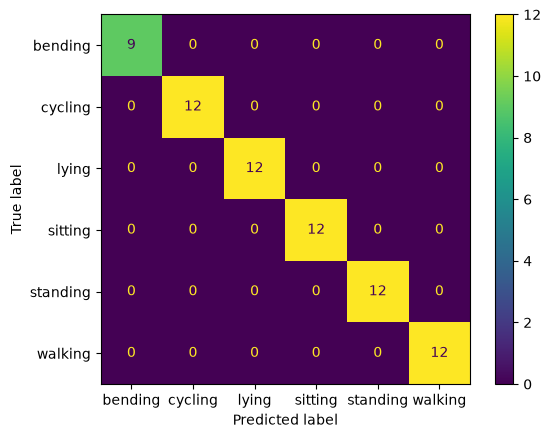

In [41]:
ConfusionMatrixDisplay.from_predictions(training_data_y_2ci, training_classifications_2ci)
plt.show()

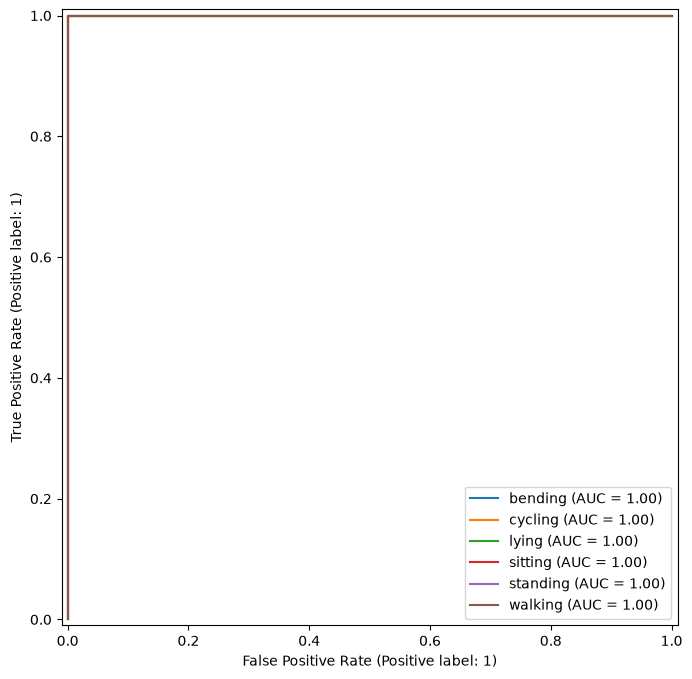

Training AUC: 1.0


In [42]:
training_probabilities_2ci = l1_pipeline_2ci.predict_proba(training_data_x_2ci)
figure_2ci, axis_2ci = plt.subplots(figsize=(8, 8))
for class_index, activity in enumerate(l1_pipeline_2ci.classes_):
    RocCurveDisplay.from_predictions(training_data_y_2ci == activity, training_probabilities_2ci[:, class_index],
                                     name=activity, ax=axis_2ci)
plt.show()
print(f"Training AUC: {roc_auc_score(training_data_y_2ci, training_probabilities_2ci, multi_class='ovr')}")

In [43]:
test_data_x_2ci = best_lC_test_data_2ci[feature_columns_2ci]
test_data_y_2ci = best_lC_test_data_2ci['activity']
test_predictions_2ci = l1_pipeline_2ci.predict(test_data_x_2ci)
test_probabilities_2ci = l1_pipeline_2ci.predict_proba(test_data_x_2ci)
test_accuracy_2ci = accuracy_score(test_data_y_2ci, test_predictions_2ci)
cross_validation_accuracy_2ci = best_grid_search_result_2ci['cross_validation_accuracy']
print(f'Cross-Validation Accuracy: {cross_validation_accuracy_2ci}')
print(f'Test Accuracy: {test_accuracy_2ci}')
print(f'Test Error: {1 - test_accuracy_2ci}')
print(f'Test ROC AUC: {roc_auc_score(test_data_y_2ci, test_probabilities_2ci, multi_class='ovr')}')

Cross-Validation Accuracy: 0.9252747252747253
Test Accuracy: 0.8421052631578947
Test Error: 0.1578947368421053
Test ROC AUC: 0.9611111111111111


For calculating multi-class ROC AUC, I used the one-versus-rest approach (https://scikit-learn.org/stable/auto_examples/model_selection/plot_roc.html#one-vs-rest-multiclass-roc), which measures the ROC AUC for each class using itself against all others as a binary problem. The test ROC AUC is an unweighted average of the classes.

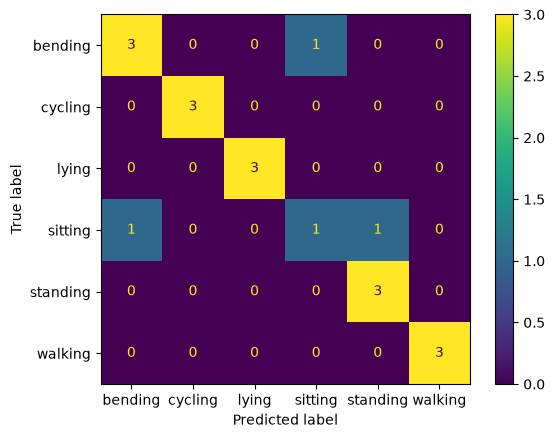

In [44]:
ConfusionMatrixDisplay.from_predictions(test_data_y_2ci, test_predictions_2ci)
plt.show()

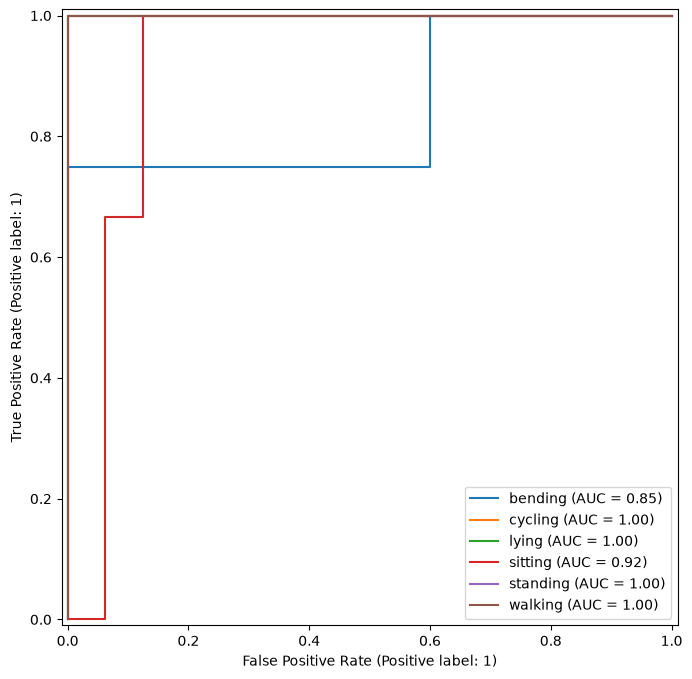

In [45]:
figure_2ci_test, axis_2ci_test = plt.subplots(figsize=(8, 8))
for class_index, activity in enumerate(l1_pipeline_2ci.classes_):
    RocCurveDisplay.from_predictions(test_data_y_2ci == activity, test_probabilities_2ci[:, class_index],
                                     name=activity, ax=axis_2ci_test)
plt.show()

To handle multi-class ROC AUC visualization, I simply plot the individual ROC curves using different colors and overlay.

#### ii. Naive Bayes

In [46]:
naive_bayes_results_2cii = []
for l in range(1, 21):
    multinomial_classification_data_l_splits_2cii \
        = extract_features(pd.concat([training_data, test_data], ignore_index=True), splits=l)
    training_multinomial_classification_data_l_splits_2cii = multinomial_classification_data_l_splits_2cii[
        multinomial_classification_data_l_splits_2cii['is_training_data'] == True]
    feature_columns_2cii = training_multinomial_classification_data_l_splits_2cii.columns.drop(
        ['instance', 'is_training_data', 'activity']).tolist()
    training_data_x_2cii = training_multinomial_classification_data_l_splits_2cii[feature_columns_2cii]
    training_data_y_2cii = training_multinomial_classification_data_l_splits_2cii['activity']
    gaussian_cross_validation_accuracy = (
        cross_val_score(GaussianNB(), training_data_x_2cii, training_data_y_2cii,
                        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=9999),
                        scoring='accuracy',
                        n_jobs=-1).mean())
    naive_bayes_results_2cii.append({'model': 'Gaussian',
                                     'l': l,
                                     'cross_validation_accuracy': gaussian_cross_validation_accuracy})
    multinomial_cross_validation_accuracy = (
        cross_val_score(MultinomialNB(), training_data_x_2cii, training_data_y_2cii,
                        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=9999),
                        scoring='accuracy',
                        n_jobs=-1).mean())
    naive_bayes_results_2cii.append({'model': 'Multinomial',
                                     'l': l,
                                     'cross_validation_accuracy': multinomial_cross_validation_accuracy})
naive_bayes_results_2cii = pd.DataFrame(naive_bayes_results_2cii)

In [47]:
best_naive_bayes_results_2cii = naive_bayes_results_2cii.loc[
    naive_bayes_results_2cii.groupby('model')['cross_validation_accuracy'].idxmax()]
display(best_naive_bayes_results_2cii)

,model,l,cross_validation_accuracy
0,Gaussian,1,0.854945
1,Multinomial,1,0.853846


In [48]:
best_gaussian_result_2cii = best_naive_bayes_results_2cii.set_index('model').loc['Gaussian']
best_l_gaussian_2cii = int(best_gaussian_result_2cii['l'])
best_l_gaussian_data_2cii = extract_features(pd.concat([training_data, test_data], ignore_index=True),
                                             splits=best_l_gaussian_2cii)
best_l_gaussian_training_data_2cii = best_l_gaussian_data_2cii[
    best_l_gaussian_data_2cii['is_training_data'] == True]
best_l_gaussian_test_data_2cii = best_l_gaussian_data_2cii[
    best_l_gaussian_data_2cii['is_training_data'] != True]
gaussian_feature_columns_2cii = best_l_gaussian_training_data_2cii.columns.drop(
    ['instance', 'is_training_data', 'activity']).tolist()
gaussian_training_data_x_2cii = best_l_gaussian_training_data_2cii[gaussian_feature_columns_2cii]
gaussian_training_data_y_2cii = best_l_gaussian_training_data_2cii['activity']
gaussian_model_2cii = GaussianNB().fit(gaussian_training_data_x_2cii, gaussian_training_data_y_2cii)

In [49]:
gaussian_training_classifications_2cii = gaussian_model_2cii.predict(gaussian_training_data_x_2cii)
gaussian_training_accuracy_2cii = accuracy_score(gaussian_training_data_y_2cii,
                                                 gaussian_training_classifications_2cii)
print(f'Training Error: {1 - gaussian_training_accuracy_2cii}')

Training Error: 0.01449275362318836


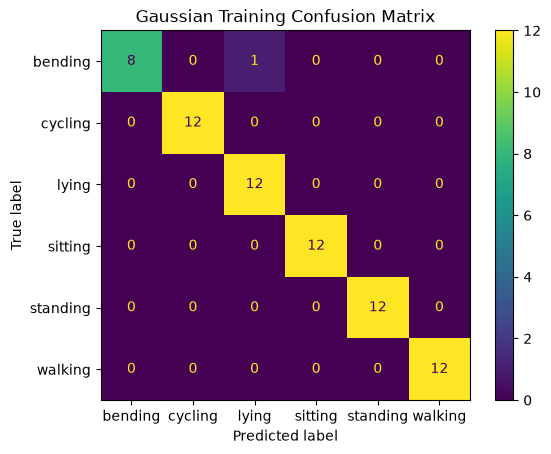

In [50]:
ConfusionMatrixDisplay.from_predictions(gaussian_training_data_y_2cii, gaussian_training_classifications_2cii)
plt.title('Gaussian Training Confusion Matrix')
plt.show()

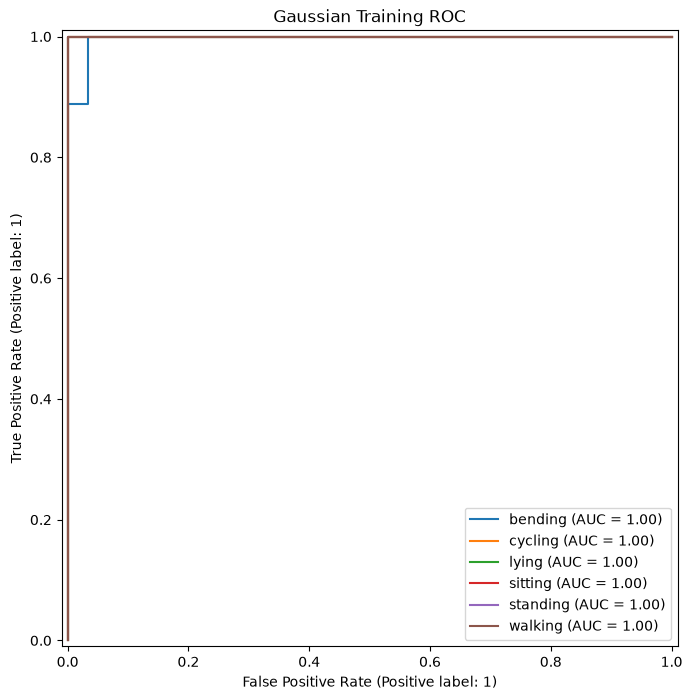

Training ROC AUC: 0.9993827160493828


In [51]:
gaussian_training_probabilities_2cii = gaussian_model_2cii.predict_proba(gaussian_training_data_x_2cii)
figure_gaussian_2cii, axis_gaussian_2cii = plt.subplots(figsize=(8, 8))
for class_index, activity in enumerate(gaussian_model_2cii.classes_):
    RocCurveDisplay.from_predictions(gaussian_training_data_y_2cii == activity,
                                     gaussian_training_probabilities_2cii[:, class_index],
                                     name=activity, ax=axis_gaussian_2cii)
plt.title('Gaussian Training ROC')
plt.show()
gaussian_training_auc_2cii = roc_auc_score(gaussian_training_data_y_2cii, gaussian_training_probabilities_2cii,
                                           multi_class='ovr')
print(f'Training ROC AUC: {gaussian_training_auc_2cii}')

In [52]:
gaussian_test_data_x_2cii = best_l_gaussian_test_data_2cii[gaussian_feature_columns_2cii]
gaussian_test_data_y_2cii = best_l_gaussian_test_data_2cii['activity']
gaussian_test_predictions_2cii = gaussian_model_2cii.predict(gaussian_test_data_x_2cii)
gaussian_test_probabilities_2cii = gaussian_model_2cii.predict_proba(gaussian_test_data_x_2cii)
gaussian_test_accuracy_2cii = accuracy_score(gaussian_test_data_y_2cii, gaussian_test_predictions_2cii)
gaussian_cross_validation_accuracy_2cii = best_gaussian_result_2cii['cross_validation_accuracy']
gaussian_test_auc_2cii = roc_auc_score(gaussian_test_data_y_2cii, gaussian_test_probabilities_2cii,
                                       multi_class='ovr')
print(f'Cross-Validation Accuracy: {gaussian_cross_validation_accuracy_2cii}')
print(f'Test Accuracy: {gaussian_test_accuracy_2cii}')
print(f'Test Error: {1 - gaussian_test_accuracy_2cii}')
print(f'Test ROC AUC: {gaussian_test_auc_2cii}')

Cross-Validation Accuracy: 0.8549450549450549
Test Accuracy: 0.8947368421052632
Test Error: 0.10526315789473684
Test ROC AUC: 0.9614583333333333


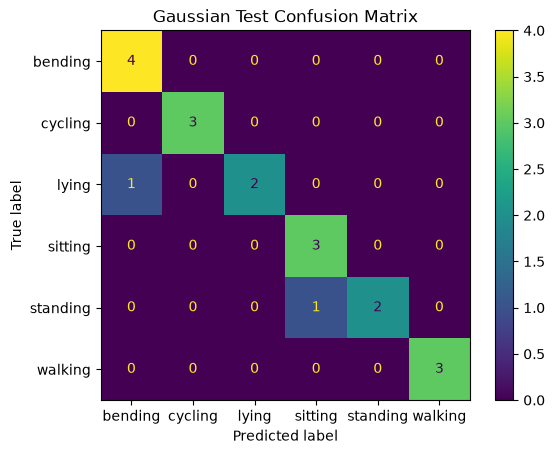

In [53]:
ConfusionMatrixDisplay.from_predictions(gaussian_test_data_y_2cii, gaussian_test_predictions_2cii)
plt.title('Gaussian Test Confusion Matrix')
plt.show()

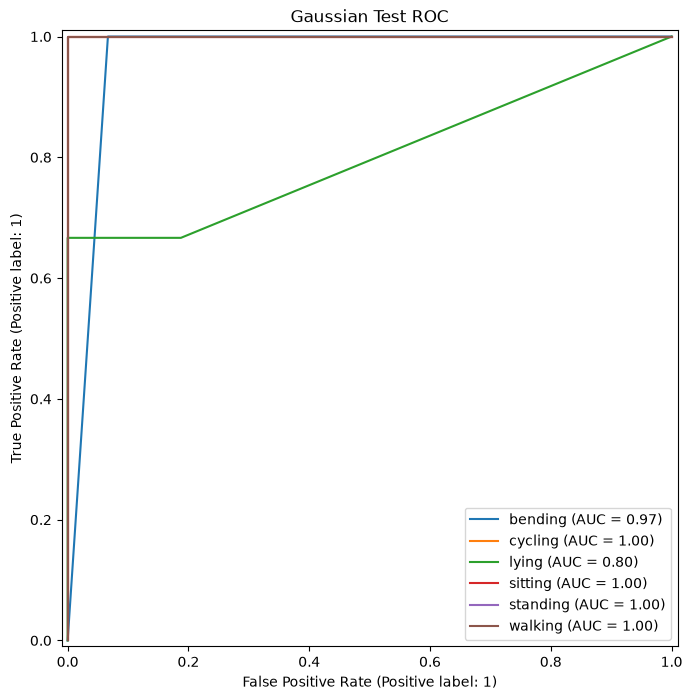

In [54]:
figure_gaussian_test_2cii, axis_gaussian_test_2cii = plt.subplots(figsize=(8, 8))
for class_index, activity in enumerate(gaussian_model_2cii.classes_):
    RocCurveDisplay.from_predictions(gaussian_test_data_y_2cii == activity,
                                     gaussian_test_probabilities_2cii[:, class_index],
                                     name=activity, ax=axis_gaussian_test_2cii)
plt.title('Gaussian Test ROC')
plt.show()

In [55]:
best_multinomial_result_2cii = best_naive_bayes_results_2cii.set_index('model').loc['Multinomial']
best_l_multinomial_2cii = int(best_multinomial_result_2cii['l'])
best_l_multinomial_data_2cii = extract_features(pd.concat([training_data, test_data], ignore_index=True),
                                                splits=best_l_multinomial_2cii)
best_l_multinomial_training_data_2cii = best_l_multinomial_data_2cii[
    best_l_multinomial_data_2cii['is_training_data'] == True]
best_l_multinomial_test_data_2cii = best_l_multinomial_data_2cii[
    best_l_multinomial_data_2cii['is_training_data'] != True]
multinomial_feature_columns_2cii = best_l_multinomial_training_data_2cii.columns.drop(
    ['instance', 'is_training_data', 'activity']).tolist()
multinomial_training_data_x_2cii = best_l_multinomial_training_data_2cii[multinomial_feature_columns_2cii]
multinomial_training_data_y_2cii = best_l_multinomial_training_data_2cii['activity']
multinomial_model_2cii = MultinomialNB().fit(multinomial_training_data_x_2cii, multinomial_training_data_y_2cii)

In [56]:
multinomial_training_classifications_2cii = multinomial_model_2cii.predict(multinomial_training_data_x_2cii)
multinomial_training_accuracy_2cii = accuracy_score(multinomial_training_data_y_2cii,
                                                    multinomial_training_classifications_2cii)
print(f'Training Error: {1 - multinomial_training_accuracy_2cii}')

Training Error: 0.07246376811594202


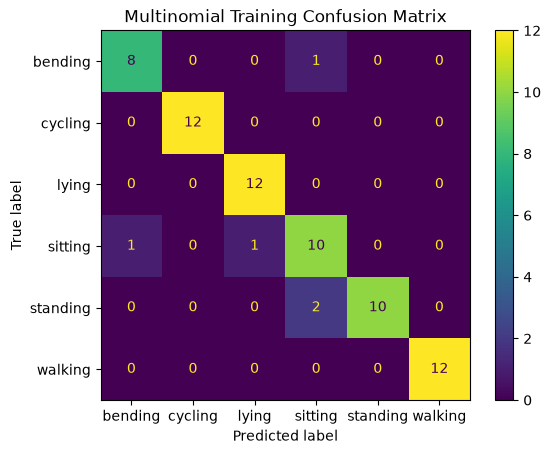

In [57]:
ConfusionMatrixDisplay.from_predictions(multinomial_training_data_y_2cii, multinomial_training_classifications_2cii)
plt.title('Multinomial Training Confusion Matrix')
plt.show()

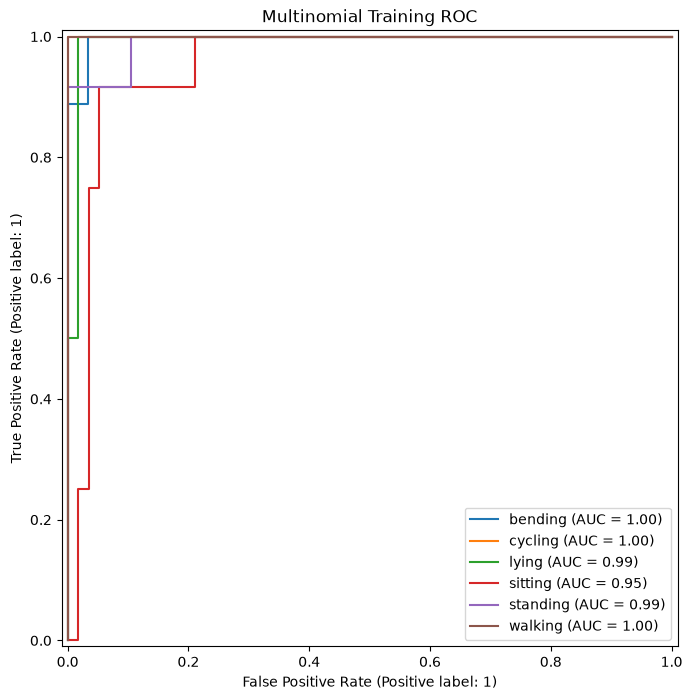

Training ROC AUC: 0.988417803768681


In [58]:
multinomial_training_probabilities_2cii = multinomial_model_2cii.predict_proba(multinomial_training_data_x_2cii)
figure_multinomial_2cii, axis_multinomial_2cii = plt.subplots(figsize=(8, 8))
for class_index, activity in enumerate(multinomial_model_2cii.classes_):
    RocCurveDisplay.from_predictions(multinomial_training_data_y_2cii == activity,
                                     multinomial_training_probabilities_2cii[:, class_index],
                                     name=activity, ax=axis_multinomial_2cii)
plt.title('Multinomial Training ROC')
plt.show()
multinomial_training_auc_2cii = roc_auc_score(multinomial_training_data_y_2cii, multinomial_training_probabilities_2cii,
                                              multi_class='ovr')
print(f'Training ROC AUC: {multinomial_training_auc_2cii}')

In [59]:
multinomial_test_data_x_2cii = best_l_multinomial_test_data_2cii[multinomial_feature_columns_2cii]
multinomial_test_data_y_2cii = best_l_multinomial_test_data_2cii['activity']
multinomial_test_predictions_2cii = multinomial_model_2cii.predict(multinomial_test_data_x_2cii)
multinomial_test_probabilities_2cii = multinomial_model_2cii.predict_proba(multinomial_test_data_x_2cii)
multinomial_test_accuracy_2cii = accuracy_score(multinomial_test_data_y_2cii, multinomial_test_predictions_2cii)
multinomial_cross_validation_accuracy_2cii = best_multinomial_result_2cii['cross_validation_accuracy']
multinomial_test_auc_2cii = roc_auc_score(multinomial_test_data_y_2cii, multinomial_test_probabilities_2cii,
                                          multi_class='ovr')
print(f'Cross-Validation Accuracy: {multinomial_cross_validation_accuracy_2cii}')
print(f'Test Accuracy: {multinomial_test_accuracy_2cii}')
print(f'Test Error: {1 - multinomial_test_accuracy_2cii}')
print(f'Test ROC AUC: {multinomial_test_auc_2cii}')

Cross-Validation Accuracy: 0.8538461538461538
Test Accuracy: 0.8947368421052632
Test Error: 0.10526315789473684
Test ROC AUC: 0.982638888888889


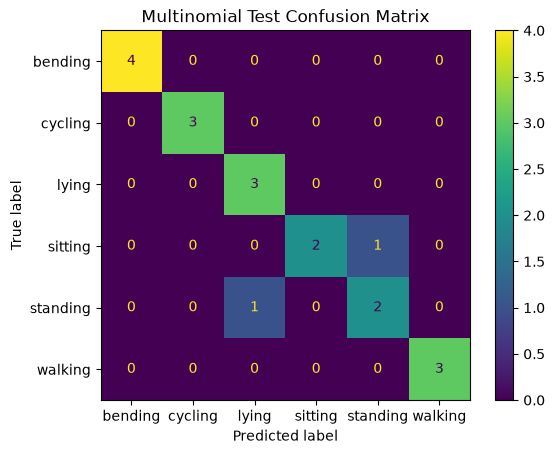

In [60]:
ConfusionMatrixDisplay.from_predictions(multinomial_test_data_y_2cii, multinomial_test_predictions_2cii)
plt.title('Multinomial Test Confusion Matrix')
plt.show()

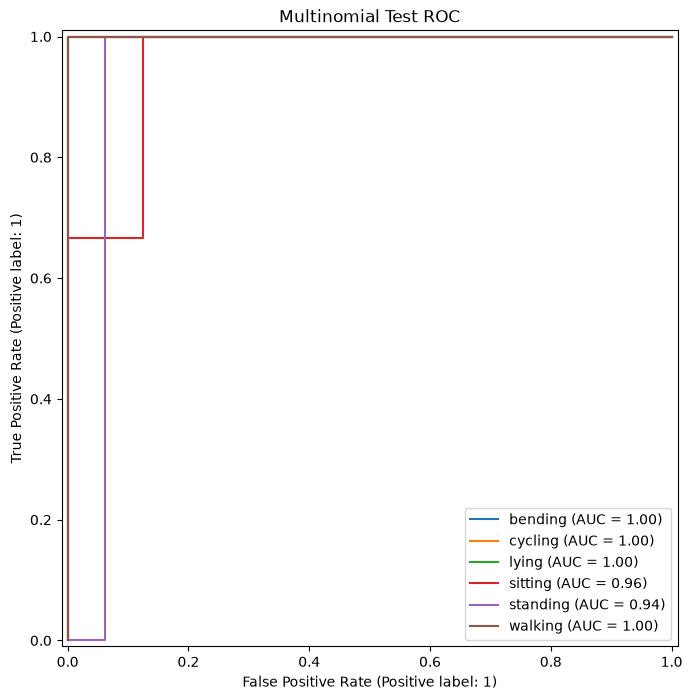

In [61]:
figure_multinomial_test_2cii, axis_multinomial_test_2cii = plt.subplots(figsize=(8, 8))
for class_index, activity in enumerate(multinomial_model_2cii.classes_):
    RocCurveDisplay.from_predictions(multinomial_test_data_y_2cii == activity,
                                     multinomial_test_probabilities_2cii[:, class_index],
                                     name=activity, ax=axis_multinomial_test_2cii)
plt.title('Multinomial Test ROC')
plt.show()

**Both Gaussian and multinomial have the same test error of 0.105, but multinomial wins on test ROC AUC with 0.983.**

#### iii. Comparison

There's not a clear winner as to which approach is better between L1-penalized multinomial logistic regression and Naive Bayes, but the former gets a slight edge. In terms of cross-validation accuracy, L1 logistic regression wins with 0.925 over Gaussian Naive Bayes with 0.855. The test errors are slightly better for Naive Bayes than L1 logistic regression (0.105 versus 0.158), but this ultimately comes down to one more incorrect prediction on 19 test data points (i.e., the verdict might not hold with a larger sample size). Multinomial Naive Bayes has a slightly better test ROC AUC than L1 logistic regression (0.983 versus 0.961) as well.

## 3. ISLR 4.8.3

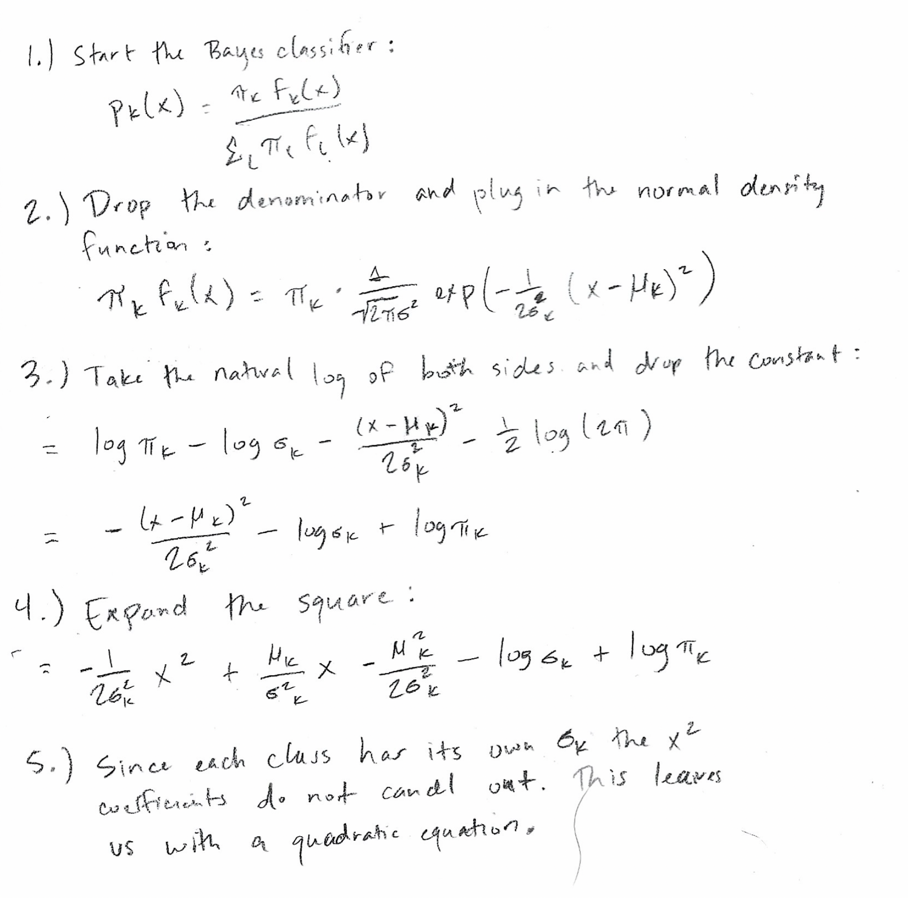

## 4. ISLR 4.8.7

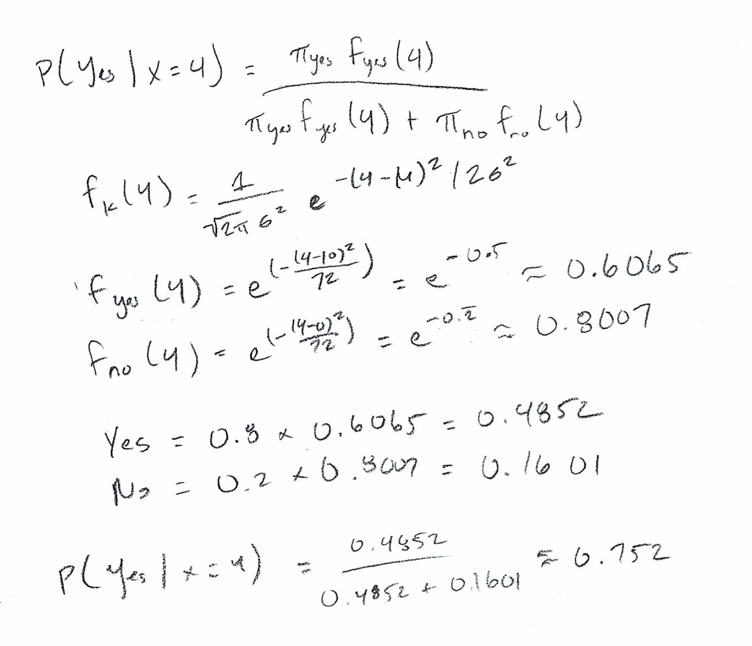